# BFMNs from association and valence task

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
import spacy
from emoatlas import EmoScores
from emoatlas.resources import _valences
from scipy import stats
from tqdm import tqdm
from collections import Counter
import json
import networkx as nx
import re
import os
import gc  # For garbage collection
import psutil  # For memory monitoring
from SpreadPy.Models.models import BaseSpreading
from SpreadPy import IOUtils, AnalyticalUtils
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler, Normalizer
import sys
import seaborn as sns
# It is recommended to use the new seaborn objects interface
import seaborn.objects as so
from typing import Any, Dict, List, Optional

# Add project root (parent of this scripts/ folder) to sys.path once
PROJECT_ROOT = os.path.abspath("..")
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

# Now import from ../src folder (qui ho creato delle funzioni utili)
from src import exporter, fmtools, fmn_valence, importer

Loaded SPACY_MODEL_PATH: /home/franaz/coding/spacy-models/it_core_news_lg/it_core_news_lg-3.7.0
Loaded NLTK_DATA: /home/franaz/nltk_data



/home/franaz/coding/python/projects/data_science/networks/rassereno/.rassereno-py310/lib/python3.10/site-packages/spacy/util.py:922: UserWarning: [W095] Model 'it_core_news_lg' (3.7.0) was trained with spaCy v3.7.0 and may not be 100% compatible with the current version (3.8.7). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)


In [2]:
# you do not need to run these download commands every time. nltk.download()
# saves these data packages to your local file system in the nltk_data directory.
# Once they are downloaded, they are available for NLTK to use in any session.

'''nltk.download('wordnet')
nltk.download('omw-1.4') # for italian and multilingual support, if needed
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng') # for word tokenization
nltk.download('averaged_perceptron_tagger') # for POS tagging
'''


"nltk.download('wordnet')\nnltk.download('omw-1.4') # for italian and multilingual support, if needed\nnltk.download('punkt')\nnltk.download('punkt_tab')\nnltk.download('averaged_perceptron_tagger_eng') # for word tokenization\nnltk.download('averaged_perceptron_tagger') # for POS tagging\n"

In [3]:
from nltk import word_tokenize, pos_tag

# Environment and models settings

In [4]:
# Set language once; everything else adapts
language = "english" # or "italian"
env_file_path = "../env"

def load_env_vars(path: str) -> None:
    if os.path.exists(path):
        with open(path) as f:
            for line in f:
                s = line.strip()
                if s and not s.startswith("#"):
                    key, value = s.split("=", 1)
                    os.environ[key] = value
        print(f"Loaded SPACY_MODEL_PATH: {os.environ.get('SPACY_MODEL_PATH')}")
        print(f"Loaded NLTK_DATA: {os.environ.get('NLTK_DATA')}\n")
    else:
        print(f"Warning: {path} file not found. Using default paths.")

def ensure_nltk_path():
    nltk_data_dir = os.environ.get("NLTK_DATA")
    if nltk_data_dir:
        try:
            import nltk
            if nltk_data_dir not in nltk.data.path:
                nltk.data.path.insert(0, nltk_data_dir)
        except Exception as e:
            print(f"Warning: could not set NLTK_DATA path: {e}")

def init_spacy_and_emo(language: str):
    SPACY_DEFAULTS = {
        "english": "en_core_web_lg",
        "italian": "it_core_news_lg",
    }
    # env overrides default
    requested = os.environ.get("SPACY_MODEL_PATH") or SPACY_DEFAULTS.get(language, "en_core_web_lg")

    def _load(model_name_or_path: str):
        try:
            return spacy.load(model_name_or_path), model_name_or_path
        except Exception as e:
            return None, e

    nlp, ok = _load(requested)
    if nlp is None:
        fallback = SPACY_DEFAULTS.get(language, "en_core_web_lg")
        if isinstance(ok, Exception):
            print(f"spaCy load failed for '{requested}': {ok}\nFalling back to '{fallback}'")
        nlp, ok2 = _load(fallback)
        if nlp is None:
            raise RuntimeError(
                f"Failed to load spaCy model. Tried '{requested}' and fallback '{fallback}'. "
                f"Install with: python -m spacy download {fallback}"
            )
        requested = fallback

    emo = EmoScores(language=language, spacy_model=requested)
    return nlp, emo

# Execute setup
load_env_vars(env_file_path)
ensure_nltk_path()

nlp, emo = init_spacy_and_emo(language)

Loaded SPACY_MODEL_PATH: /home/franaz/coding/spacy-models/it_core_news_lg/it_core_news_lg-3.7.0
Loaded NLTK_DATA: /home/franaz/nltk_data



In [5]:
pd.set_option('display.max_rows', 100)

# fmn and paths settings

In [6]:
# Dynamic output paths system for pipelines
base_output_path = '../out'
project_name = 'merged'
formatted_data_dir = 'formatting'
# Set the type of fmn to use: 'bfmns' or 'tfmns'
# (this is used for the folder name, not for the file names)
fmn_type = 'bfmns'
# Keywords that we want to check for in the textual data. If not empty,
# semantic frame plots will be created for these keywords. Otherwise,
# the full FMNs will be visualized.
keywords = []
keywords =['mathematics','anxiety','stress','depression','statistics','computer','science','physics','science','performance','exam','grade','evaluation','school','competition','university','calculation','discipline','subject']
# Lemmatization setting
lemmatize = False

# Types of output: aggregated and individual (entire dataset vs per participant FMNs)
# Choose any subset: {'aggregated'}, {'individual'}, or both
# How to use:
# Only aggregated: methods = {'aggregated'}
# Only individual: methods = {'individual'}
# Both: methods = {'aggregated', 'individual'}
ALLOWED_METHODS = {'aggregated', 'individual'}
methods = {'aggregated'}
methods = {m.strip().lower() for m in (methods if isinstance(methods, (list, set, tuple)) else [methods])}
methods = methods & ALLOWED_METHODS
if not methods:
    raise ValueError("No valid methods selected. Use 'aggregated' and/or 'individual'.")

# Groups to subset the data (if needed). Use labels and .startswith() condition
# from the 'participant_id' column to create groups.
group_name = 'researchers_filtered'  # fmn name when using groups
if group_name:
    fmn_type = f'{group_name}_{fmn_type}'

# If dfs_and_group_labels is longer than 1, merge the data from the different paths.
dfs_and_group_labels = []
df1 = pd.read_csv('../out/formatting/splitted_dfs/high_anxiety_high_school_gpt_oss.csv')
dfs_and_group_labels = [
    (df1, None)   # list of (df, group_labels)
]

# print all unique participants
all_participants = set()
for df, group_labels in dfs_and_group_labels:
    all_participants.update(df['participant_id'].unique())
print(f"All unique participants across datasets: {len(all_participants)}")
print(f"Unique participants labels: {all_participants}\n")

# Resolve output directories
if methods == {'aggregated'}:
    files_output_dir = f'{base_output_path}/{project_name}/aggregated/{fmn_type}'
    data_output_dir = f'{base_output_path}/{project_name}/aggregated/{formatted_data_dir}/{fmn_type}'
if methods == {'individual'}:
    files_output_dir = f'{base_output_path}/{project_name}/individual/{fmn_type}'
    data_output_dir = f'{base_output_path}/{project_name}/individual/{formatted_data_dir}/{fmn_type}'

All unique participants across datasets: 28
Unique participants labels: {'gpt_oss_882', 'gpt_oss_131', 'gpt_oss_508', 'gpt_oss_643', 'gpt_oss_253', 'gpt_oss_706', 'gpt_oss_196', 'gpt_oss_540', 'gpt_oss_745', 'gpt_oss_107', 'gpt_oss_972', 'gpt_oss_226', 'gpt_oss_960', 'gpt_oss_290', 'gpt_oss_126', 'gpt_oss_195', 'gpt_oss_269', 'gpt_oss_579', 'gpt_oss_847', 'gpt_oss_095', 'gpt_oss_949', 'gpt_oss_439', 'gpt_oss_305', 'gpt_oss_748', 'gpt_oss_128', 'gpt_oss_721', 'gpt_oss_547', 'gpt_oss_223'}



### Data pre-processing functions

In [7]:
def get_wordnet_pos(treebank_tag):
    """Convert POS tag to a format recognized by WordNetLemmatizer."""
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN  # Default to noun

# Lemmatization function for English text using NLTK
def lemmatize_text(text):
    tokens = word_tokenize(text)
    pos_tags = pos_tag(tokens)
    lemmatizer = WordNetLemmatizer()
    lemmatized_tokens = [
        lemmatizer.lemmatize(token, get_wordnet_pos(pos)) for token, pos in pos_tags
    ]
    return ' '.join(lemmatized_tokens)

# Lemmatization for Italian text using spaCy (NLTK lemmatization is in English)
def lemmatize_text_it(text):
    doc = nlp(text)
    return ' '.join([token.lemma_ for token in doc])

## Dataframe preparation

In [8]:
def _normalize_token(x: str):
    '''Normalize a token by lowercasing and removing punctuation/numbers.
    It’s used in build_association_df to normalize cue and association fields.

    Parameters
    ----------
    x : str
        The input token to normalize.

    Returns
    -------
    str or None
        The normalized token, or None if the input is None or results in an empty string.
    '''
    if x is None or pd.isna(x):
        return None
    x = str(x).lower()
    x = re.sub(r'[\d\W_]+', ' ', x)      # rimuovi punteggiatura/numeri
    x = re.sub(r'\s+', ' ', x).strip()
    return x if x else None


def build_association_df(df: pd.DataFrame, lemmatize: bool = False, lang: str = "italian") -> pd.DataFrame:
    '''Convert a wide-format DataFrame into long format with optional lemmatization.
       - No caching.
       - No preservation of original raw columns.
    '''
    assoc_pattern = re.compile(r"^association_(\d+)$")
    association_numbers = sorted({
        int(m.group(1)) for col in df.columns for m in [assoc_pattern.match(col)] if m
    })

    def _lem(s: str) -> str:
        if not isinstance(s, str) or not s:
            return s
        try:
            if lang.lower().startswith("it"):
                return lemmatize_text_it(s)
            else:
                return lemmatize_text(s)
        except Exception:
            return s

    records = []
    for _, row in df.iterrows():
        participant_id = row.get("participant_id")
        cue_raw = row.get("cue_word")
        norm_cue = _normalize_token(cue_raw)
        if norm_cue is not None and lemmatize:
            norm_cue = _lem(norm_cue)

        # Add cue row (index 0) if present
        if norm_cue is not None:
            val_cue = pd.to_numeric(row.get("valence_cue_word"), errors="coerce")
            records.append({
                "participant_id": participant_id,
                "cue_word": norm_cue,
                "index": 0,
                "word": norm_cue,
                "valence": val_cue
            })

        # Add association rows
        for n in association_numbers:
            word_col = f"association_{n}"
            val_col = f"valence_association_{n}"
            if word_col not in df.columns:
                continue
            raw_word = row.get(word_col)
            norm_word = _normalize_token(raw_word)
            if norm_word is None:
                continue
            if lemmatize:
                norm_word = _lem(norm_word)

            val_raw = row.get(val_col) if val_col in df.columns else None
            numeric_valence = pd.to_numeric(val_raw, errors="coerce")
            records.append({
                "participant_id": participant_id,
                "cue_word": norm_cue,
                "index": n,
                "word": norm_word,
                "valence": numeric_valence
            })

    long_df = pd.DataFrame.from_records(records)
    if not long_df.empty:
        long_df["index"] = long_df["index"].astype(int)
        long_df["valence"] = pd.to_numeric(long_df["valence"], errors="coerce")
    return long_df


def subset_by_group_labels(dfs_and_group_labels: list, col: str) -> pd.DataFrame:
    '''Subset the input DataFrames by group labels in a specific column.
    Merge the subsets into a single DataFrame and return it.
    All dataframes must be in the same format (i.e., same columns).
    For each DataFrame, a group of specific labels is used to filter rows in it.
    The filtered rows from each DataFrame are then merged into a single DataFrame.
    If group_labels is None or empty for a specific DataFrame, all rows are included.
    Parameters:
            dfs_and_group_labels : list
                A list of tuples where each tuple contains (DataFrame, list_of_group_labels).
            col : str
                The column name to filter by group labels.
    Returns:
            pd.DataFrame
                The merged DataFrame containing only rows with specified group labels.
    '''
    if len(dfs_and_group_labels) == 0:
        raise ValueError("The input list is empty.")
    
    # Extract DataFrames from tuples for column validation
    dataframes = [df for df, _ in dfs_and_group_labels]
    
    # Ensure all DataFrames have the same columns.
    base_columns = set(dataframes[0].columns)
    for df in dataframes[1:]:
        if set(df.columns) != base_columns:
            raise ValueError("All DataFrames must have the same columns.")
    
    # Subset each DataFrame by the specified group labels in col.
    subset_dfs = []
    for df, group_labels in dfs_and_group_labels:
        if group_labels:
            # Filter rows where label .startswith. any of the group_labels
            # In the created subset, NaN values in col are excluded.
            subset = df[df[col].str.startswith(tuple(group_labels), na=False)]
        else:
            # If group_labels is None or empty, include all rows.
            subset = df.copy()
        subset_dfs.append(subset)

    # Merge all subsets into a single DataFrame.
    merged_df = pd.concat(subset_dfs, ignore_index=True)

    return merged_df

### Valence categorization and distribution

In [9]:
# Unused for now (we might need it later)
def categorize_valence_single(df):
    
    # convert to NumPy array
    arr = np.array(df['valence'])

    # compute value range (gamma)
    minv, maxv = arr.min(), arr.max()
    gamma = maxv - minv

    # if values are too close together, return all neutral --> if gamma ≤ 1 (gamma = 0 and gamma < 1 included)
    # return pd.Series([0] * len(arr), index=valence_series.index)
    if gamma <= 1:
        df['valence_cat'] = 0

    # if gamma > 1: use inclusive quartiles to classify
    Q1, Q3 = np.percentile(arr, [25, 75])

    # defines classification logic based on position relative to quartiles
    def cat_score(v):
        if v <= Q1:
            return -1  # negative
        elif v >= Q3:
            return 1   # positive
        else:
            return 0   # neutral

    # apply classification to the new "valence" column of the long form df
    df['valence_cat'] = df['valence'].apply(cat_score)

    return df


# function to plot valence categories distrubution
def plot_valence_distribution(df):
    '''Plot the distribution of valence categories in the DataFrame.
    '''
    plt.figure(figsize=(6,5))

    # count the number of occurrences of each valence category
    # and return the sorted df
    counts = df['valence_cat'].value_counts().sort_index()
    tick_positions = range(len(counts)) 
    counts.plot(kind='bar')

    plt.title('Valence categories distribution')
    plt.xlabel('Category')
    plt.ylabel('Count')
    plt.xticks(tick_positions, labels=['-1 (Negative)', '0 (Neutral)', '+1 (Positive)'], rotation=0)

    plt.tight_layout()
    plt.show()


def categorize_valence_multiple(df, alpha=0.1, min_occurrences=1, return_custom_valences=False, direction_stat="mean", normalize=False):
    """
    Global (pooled) nonparametric per-word valence categorization (Kruskal-Wallis).
    direction_stat: 'median' (default) or 'mean' to decide if positive, negative or neutral after significance.
    If normalize=True, lowercase/strip the 'word' column inside this function.
    """
    # Do not drop NaNs in valence early because we need as much
    # word occurrences as possible for the statistical test.
    # Work on a copy to avoid modifying the original DataFrame
    df = df.copy()

    # Ensure 'word' column is string type and normalize if requested
    df['word'] = df['word'].astype("string")
    if normalize:
        df['word'] = df['word'].str.strip().str.lower()

    # Check for possible mojibakes (encoding issues)
    for word in df['word']:
        if isinstance(word, str) and ('Ã' in word or 'ã' in word):
            print(f"\nWarning! Found problematic character in word: {word}\n")

    # Find number of NaNs in each column
    cols = ['cue_word', 'word', 'valence']
    for col in cols:
        if df[col].isna().sum() > 0:
            print(f"Missing values (NaNs) found in '{col}': {df[col].isna().sum()}\n")

    # Get unique words excluding NaNs
    unique_words = list(pd.Series(df['word'].unique().dropna()))

    # Initialize valence_map to store the valence category for each word
    valence_map = {}
    val_series = df['valence']

    for w in unique_words:
        mask = df['word'] == w
        print(f"N. of '{w}' occurrences: {mask.sum()}")

        if val_series[mask].isna().sum() > 0:
            print(f"Important! Found NaNs in valence series for word '{w}': {val_series[mask].isna().sum()}")

        # Get the valence scores for the current word (ignoring NaNs) in a Series
        word_valences = val_series[mask].dropna().astype(float)

        if len(word_valences) < min_occurrences:
            valence_map[w] = 0
            continue

        other_vals = val_series[~mask].dropna().astype(float)
        if len(other_vals) == 0:
            valence_map[w] = 0
            continue
        
        # Perform Kruskal-Wallis test
        stat, p_value = stats.kruskal(word_valences, other_vals)
        print(f"Kruskal-Wallis test for word '{w}': stat={stat}, p-value={p_value}\n")

        if direction_stat == "median":
            word_v_center = word_valences.median()
            other_v_center = other_vals.median()
        else:
            word_v_center = word_valences.mean()
            other_v_center = other_vals.mean()

        if p_value < alpha:
            if word_v_center < other_v_center:
                valence_map[w] = -1
            elif word_v_center > other_v_center:
                valence_map[w] = 1
            else:
                valence_map[w] = 0
        else:
            valence_map[w] = 0

    # Map the valence categories back to the original column
    df['valence_cat'] = df['word'].map(valence_map).astype('Int64')

    # Create custom valences in the order: [positive, negative, neutral]
    positive, negative, neutral = set(), set(), set()
    custom_valences = [positive, negative, neutral]
    for word, cat in valence_map.items():
        if cat == 1:
            custom_valences[0].add(word)  # positive
        elif cat == -1:
            custom_valences[1].add(word)  # negative
        else:
            custom_valences[2].add(word)  # neutral

    if return_custom_valences:
        return df, custom_valences
    return df

## Forma Mentis Networks functions

In [10]:
def build_participants_bfmns(
    df,
    emo=emo,
    directed=False,
    lemmatize=False,
    keep_original_columns=True
):
    """
    Builds one BFMN per participant_id from a long DataFrame with required columns:
        participant_id, cue_word, word, index, valence_cat (already computed globally).

    Notes:
        Rows with index == 0 register the cue node (no edge should be created from cue to itself).
        Rows with index > 0 where word == cue_word are ignored to avoid self-loops.

    Optional lemmatization (italian, spaCy):
        If lemmatize=True:
            - Columns 'cue_word_lemma' and 'word_lemma' are created.
            - Nodes and edges use lemmatized forms.
            - Valence is propagated at lemma level: conflicts resolved by majority class; ties -> 0 (neutral).

    Parameters:
        df : long-format DataFrame.
        emo : an initialized EmoScores class object.
        directed : bool, if True uses nx.DiGraph (directed) else nx.Graph (undirected). Default: False (undirected).
        lemmatize : bool, apply italian lemmatization.
        keep_original_columns : bool, if False drop auxiliary lemma columns at the end.

    Returns:
        all_bfmns : dict {participant_id: FormamentisNetwork}
        node_val_maps : dict {participant_id: {node: valence_cat}}
    """
    required_cols = {"participant_id", "cue_word", "word", "index", "valence_cat"}
    missing = required_cols - set(df.columns)
    if missing:
        raise ValueError(f"Mancano colonne richieste: {missing}")

    work_df = df.copy()

    if lemmatize:
        # secure lemmatization (keeps NaN)
        def _safe_lem(x):
            if pd.isna(x):
                return x
            try:
                return lemmatize_text_it(str(x))
            except Exception:
                return x  # fallback

        work_df["cue_word_lemma"] = work_df["cue_word"].apply(_safe_lem)
        work_df["word_lemma"] = work_df["word"].apply(_safe_lem)

        # Propagazione valenze ai lemmi:
        # Se lo stesso lemma riceve etichette diverse, usa la moda; se parità -> 0 (neutro)
        lemma_groups = (
            work_df.dropna(subset=["word_lemma"])
            .groupby("word_lemma")["valence_cat"]
            .agg(lambda s: _resolve_valence_conflicts(s))
        )
        # Mappa lemma -> valence_cat aggregata
        lemma_val_map = lemma_groups.to_dict()

    def _resolve_valence_conflicts(series):
        # Return a Series containing counts of unique values in descending order
        counts = series.value_counts(dropna=True)
        if counts.empty:
            return 0
        if len(counts) == 1:
            return counts.index[0]
        # If there is tie between different categories => neutral (0)
        top = counts[counts == counts.max()].index.tolist()
        return 0 if len(top) > 1 else top[0]

    all_bfmns = {}
    features_rows = []

    node_val_maps = {}  # store per-participant node valences

    requested_graph_type = nx.DiGraph if directed else nx.Graph

    for participant_id, p_df in tqdm(work_df.groupby("participant_id"), desc="Building BFMNs"):
        G = requested_graph_type()

        if lemmatize:
            # Use lemmatized forms for nodes and edges
            node_df = (
                p_df[["word_lemma", "valence_cat"]]
                .dropna(subset=["word_lemma"])
                .drop_duplicates()
                .rename(columns={"word_lemma": "node"})
            )
            # Replace valence with aggregated one (if present)
            node_df["valence_cat"] = node_df["node"].map(lemma_val_map).fillna(node_df["valence_cat"]).astype(int)
        else:
            node_df = (
                p_df[["word", "valence_cat"]]
                .dropna(subset=["word"])
                .drop_duplicates()
                .rename(columns={"word": "node"})
            )

        for node, vcat in node_df.itertuples(index=False):
            label = "positive" if vcat == 1 else "negative" if vcat == -1 else "neutral"
            G.add_node(node, valence=label, valence_cat=int(vcat))

        # cue edges -> response (esclude index==0 e self-loop)
        assoc_rows = p_df[(p_df["index"] > 0)]
        if lemmatize:
            assoc_rows = assoc_rows.dropna(subset=["cue_word_lemma", "word_lemma"])
            assoc_rows = assoc_rows[assoc_rows["cue_word_lemma"] != assoc_rows["word_lemma"]]
            edge_iter = zip(assoc_rows["cue_word_lemma"], assoc_rows["word_lemma"])
        else:
            assoc_rows = assoc_rows.dropna(subset=["cue_word", "word"])
            assoc_rows = assoc_rows[assoc_rows["cue_word"] != assoc_rows["word"]]
            edge_iter = zip(assoc_rows["cue_word"], assoc_rows["word"])

        G.add_edges_from(edge_iter)

        # Create FMN object from nx graph. All edges are considered as syntactic
        fmnt = emo.nxgraph_to_formamentis(G)

        # Collect node valences separately (cannot attach to namedtuple)
        node_val_maps[participant_id] = {n: d.get("valence_cat") for n, d in G.nodes(data=True)}

        # Store in dict
        all_bfmns[participant_id] = fmnt

    if lemmatize and not keep_original_columns:
        drop_cols = ["cue_word_lemma", "word_lemma"]
        work_df.drop(columns=[c for c in drop_cols if c in work_df.columns], inplace=True)

    return all_bfmns, node_val_maps


# A function that builds aggregated BFMNs from a CSV file (categorized valence)
def build_aggregated_bfmn(df, resolve_strategy="majority"):
    '''Build an aggregated undirected forma mentis network from the association dataframe.
       Removes self-loops and duplicate undirected edges.
       Returns (fmn, node_val_map) where node_val_map is {node: valence_cat_int}.
       resolve_strategy: "majority" (ties -> 0) or "first".
    '''
    G = nx.Graph()
    edges = []
    skipped_self_loops = 0
    skipped_missing = 0

    required_cols = {"participant_id", "cue_word", "word", "index", "valence_cat"}
    missing = required_cols - set(df.columns)
    if missing:
        raise ValueError(f"Mancano colonne richieste: {missing}")

    work_df = df.copy()

    # Collect valence evidence for each node (both cue_word and word)
    cue_df = (
        work_df[["cue_word", "valence_cat"]]
        .dropna(subset=["cue_word"])
        .rename(columns={"cue_word": "node"})
    )
    assoc_df = (
        work_df[["word", "valence_cat"]]
        .dropna(subset=["word"])
        .rename(columns={"word": "node"})
    )
    valence_evidence = pd.concat([cue_df, assoc_df], ignore_index=True)

    def _resolve_valence(series):
        if resolve_strategy == "first":
            return int(series.iloc[0])
        # majority strategy
        counts = series.value_counts(dropna=True)
        if counts.empty:
            return 0
        top = counts[counts == counts.max()].index.tolist()
        return 0 if len(top) > 1 else int(top[0])

    node_val_map = (
        valence_evidence.groupby("node")["valence_cat"]
        .agg(_resolve_valence)
        .to_dict()
    )

    for _, row in work_df.iterrows():
        cue = row.get('cue_word')
        association = row.get('word')

        # Skip missing
        if pd.isna(cue) or pd.isna(association):
            skipped_missing += 1
            continue

        cue = str(cue).strip()
        association = str(association).strip()
        if not cue or not association:
            skipped_missing += 1
            continue

        # Skip self-records: index==0 rows and cue==association
        if ('index' in work_df.columns and row.get('index', None) == 0) or (cue == association):
            skipped_self_loops += 1
            continue

        # Add nodes (attributes assigned later)
        G.add_node(cue)
        G.add_node(association)
        edges.append((cue, association))

    # Deduplicate undirected edges
    undirected_edges = list({tuple(sorted(e)) for e in edges})

    print(f"Skipped self-loops: {skipped_self_loops} | Skipped missing/empty: {skipped_missing}")
    print(f"Candidate edges: {len(edges)} | Unique undirected edges: {len(undirected_edges)}")

    G.add_edges_from(undirected_edges)
    print(f"Number of edges in graph: {G.number_of_edges()}")
    print(f"Number of unique cue words: {work_df['cue_word'].nunique(dropna=True)}")
    print(f"Number of unique associated words: {work_df['word'].nunique(dropna=True)}")

    # Assign valence attributes
    for n in G.nodes():
        vcat = int(node_val_map.get(n, 0))
        label = "positive" if vcat == 1 else "negative" if vcat == -1 else "neutral"
        G.nodes[n]["valence_cat"] = vcat
        G.nodes[n]["valence"] = label

    fmn = emo.nxgraph_to_formamentis(G)
    return fmn, node_val_map


def monitor_memory():
    """Monitor current memory usage"""
    process = psutil.Process(os.getpid())
    memory_mb = process.memory_info().rss / 1024 / 1024
    print(f"Current memory usage: {memory_mb:.2f} MB")
    return memory_mb


def extract_bfmn_structural_features(fmnts, save_path, emo=emo, batch_size=10, node_valence_maps=None, persist=True):
    """
    Extract, export and persist (if persist) per-participant network structural features.
    Writes one JSON and one .txt per FMN under output_dir/output_subdir.

    Parameters:
    fmnts (dict): {participant_id: FormaMentisNetwork}
    save_path (str): Base output directory
    emo (EmoScores): Initialized EmoScores object
    batch_size (int): Batch size
    node_valence_maps (dict or None): {participant_id: {node: valence_cat_int(-1,0,1)}}

    Returns:
    dict: {participant_id: structural_features_dict}
    """
    if not os.path.exists(save_path):
        os.makedirs(save_path)
    output_dir = save_path
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)

    def _sanitize_number(x):
        '''Sanitize number by converting to float and handling NaN/Inf
        '''
        try:
            if x is None:
                return None
            if isinstance(x, (float, int)):
                if isinstance(x, float) and (np.isnan(x) or np.isinf(x)):
                    return None
                return float(x)
        except Exception:
            return None
        return x

    def _valence_label(vcat):
        '''Map valence category to label'''
        if vcat == 1:
            return "positive"
        if vcat == -1:
            return "negative"
        return "neutral"

    # Create a list of (participant_id, fmnt) tuples for batching
    items = list(fmnts.items())
    total_items = len(items)
    print(f"Extracting features from {total_items} networks in batches of {batch_size}")
    # Initial memory usage
    monitor_memory()

    net_str_features_dict = {}

    for i in range(0, total_items, batch_size):
        batch_items = items[i:i+batch_size]
        print(f"\nProcessing batch {i//batch_size + 1}/{(total_items + batch_size - 1)//batch_size}")

        for fmn_title, fmnt in batch_items:
            if not hasattr(fmnt, "vertices") or len(fmnt.vertices) == 0:
                print(f"Skipping {fmn_title}: empty network.")
                continue

            # Build an undirected NX graph from the FMN
            G = nx.Graph()
            G.add_nodes_from(fmnt.vertices)
            G.add_edges_from(fmnt.edges)

            # Apply node valence attributes if provided (fallback neutral)
            node_val_map = {}
            if isinstance(node_valence_maps, dict):
                node_val_map = node_valence_maps.get(fmn_title, {}) or {}

            # Each node ends up with both a numeric (valence_cat) and string (valence)
            # attribute, enabling later feature calculations (counts, assortativity)
            # and readable outputs.
            for n in G.nodes():
                # Get the valence category for the node (default 0 if not found)
                vcat = node_val_map.get(n, 0)
                # Sanitize and assign the valence attributes for the node.
                # Both numeric and string attributes for valence are set.
                G.nodes[n]["valence_cat"] = int(vcat) if vcat is not None else 0
                G.nodes[n]["valence"] = _valence_label(G.nodes[n]["valence_cat"])

            # Basic counts
            n_nodes = G.number_of_nodes()
            n_edges = G.number_of_edges()
            n_pos = sum(1 for _, d in G.nodes(data=True) if d.get("valence_cat") == 1)
            n_neg = sum(1 for _, d in G.nodes(data=True) if d.get("valence_cat") == -1)

            # Degree stats (undirected graph)
            degrees = [d for _, d in G.degree()]
            min_degree = min(degrees) if degrees else 0
            max_degree = max(degrees) if degrees else 0

            # Local graph-level average clustering.
            # It is the mean of the local clustering coefficients of all the nodes in the graph.
            try:
                # Try the standard method first (more accurate)
                avg_clust = nx.average_clustering(G) if n_nodes > 1 else 0.0
            except Exception:
                try:
                    # Fallback to approximation (less accurate but more robust)
                    avg_clust = nx.algorithms.approximation.clustering_coefficient.average_clustering(G)
                except Exception:
                    avg_clust = None

            # Degree assortativity
            try:
                degree_assortativity = nx.degree_assortativity_coefficient(G)
            except Exception:
                degree_assortativity = None

            # Attribute assortativity for 'valence'
            try:
                valence_assortativity = nx.attribute_assortativity_coefficient(G, "valence")
            except Exception:
                valence_assortativity = None

            # Closeness centrality extremes
            try:
                closeness = nx.closeness_centrality(G)
                max_closeness = max(closeness.values()) if closeness else None
                min_closeness = min(closeness.values()) if closeness else None
            except Exception:
                max_closeness = None
                min_closeness = None

            # ASPL, diameter, nodes and edges of the largest connected component
            # LCC + path stats
            if n_nodes == 0:
                lcc_aspl = None
                lcc_diameter = None
                lcc_nodes = 0
                lcc_edges = 0
            elif n_nodes == 1:
                lcc_aspl = 0.0
                lcc_diameter = 0
                lcc_nodes = 1
                lcc_edges = 0
            else:
                try:
                    undirected_G = G.to_undirected() if G.is_directed() else G
                    if nx.is_connected(undirected_G):
                        H = undirected_G
                    else:
                        largest_cc = max(nx.connected_components(undirected_G), key=len)
                        H = undirected_G.subgraph(largest_cc).copy()
                    lcc_nodes = H.number_of_nodes()
                    lcc_edges = H.number_of_edges()
                    lcc_aspl = nx.average_shortest_path_length(H) if lcc_nodes > 1 else 0.0
                    lcc_diameter = nx.diameter(H) if lcc_nodes > 1 else 0
                except Exception:
                    lcc_aspl = None
                    lcc_diameter = None
                    lcc_nodes = H.number_of_nodes() if 'H' in locals() else 0
                    lcc_edges = H.number_of_edges() if 'H' in locals() else 0

            # Compute z-scores using emo module
            try:
                zscores = emo.zscores(fmnt)
            except Exception:
                zscores = {}

            # Compute local clustering
            try:
                local_clustering = nx.clustering(G)
            except Exception:
                local_clustering = {}

            # Compute hubs: top 5 concepts by highest degree
            try:
                # DegreeView is iterable of (node, degree) pairs; convert/sort directly
                degree_pairs = list(G.degree())
                sorted_degrees = sorted(degree_pairs, key=lambda x: x[1], reverse=True)[:5]
            except Exception:
                sorted_degrees = []

            structural_features = {
                "n_nodes": n_nodes,
                "n_edges": n_edges,
                "n_positive_nodes": n_pos,
                "n_negative_nodes": n_neg,
                "min_degree": _sanitize_number(min_degree),
                "max_degree": _sanitize_number(max_degree),
                "average_clustering": _sanitize_number(avg_clust),
                "local_clustering": {k: _sanitize_number(v) for k, v in local_clustering.items()},
                "degree_assortativity": _sanitize_number(degree_assortativity),
                "valence_assortativity": _sanitize_number(valence_assortativity),
                "max_closeness_centrality": _sanitize_number(max_closeness),
                "min_closeness_centrality": _sanitize_number(min_closeness),
                "lcc_nodes": _sanitize_number(lcc_nodes),
                "lcc_edges": _sanitize_number(lcc_edges),
                "lcc_average_shortest_path_length": _sanitize_number(lcc_aspl),
                "lcc_diameter": _sanitize_number(lcc_diameter),
                "zscores": {k: _sanitize_number(v) for k, v in zscores.items()},
                "top_5_hubs_by_degree": [{"node": n, "degree": _sanitize_number(d)} for n, d in sorted_degrees],
            }

            # Save structural features in JSON
            out_path_json = os.path.join(output_dir, f"{fmn_title}_structural_features.json")
            with open(out_path_json, "w", encoding="utf-8") as f:
                json.dump(structural_features, f, ensure_ascii=False, indent=2)
            print(f"Saved at {out_path_json}")

            # Save TXT dump
            out_path_txt = os.path.join(output_dir, f"{fmn_title}_structural_features.txt")
            with open(out_path_txt, "w", encoding="utf-8") as f:
                for k, v in structural_features.items():
                    f.write(f"{k}: {v}\n")
            print(f"Saved at {out_path_txt}")

            net_str_features_dict[fmn_title] = structural_features

        monitor_memory()
        gc.collect()

    print(f"Saved structural features for {len(net_str_features_dict)} networks\n")
    return net_str_features_dict


# An updated version of emo.export_whole_fmnt() that supports custom valence exports.
def export_whole_fmn_custom(fmnt, save_path, custom_valences, language="english"):
    """
    Export a FMN with optional custom valence node lists.
    """
    # Collect edges robustly (handles dict-of-layers or flat iterables)
    def _collect_edges(f):
        edges_attr = getattr(f, "edges", None)
        out = []
        if edges_attr is None:
            return out
        if isinstance(edges_attr, dict):
            for lst in edges_attr.values():
                for e in lst:
                    if isinstance(e, (list, tuple)) and len(e) >= 2:
                        out.append((e[0], e[1]))
        else:
            for e in edges_attr:
                if isinstance(e, (list, tuple)) and len(e) >= 2:
                    out.append((e[0], e[1]))
        return out

    edges = _collect_edges(fmnt)

    # Include all nodes: vertices union edge endpoints
    all_nodes = set(getattr(fmnt, "vertices", []) or [])
    for u, v in edges:
        all_nodes.update([u, v])

    # Build node lists
    if custom_valences:
        if not isinstance(custom_valences, (list, tuple)) or len(custom_valences) != 3:
            raise ValueError("custom_valences must be [positive_set, negative_set, neutral_set]")
        pos_set, neg_set, neu_set = custom_valences
        if not all(isinstance(s, set) for s in (pos_set, neg_set, neu_set)):
            raise ValueError("custom_valences elements must be sets")
        positive_nodes = sorted([n for n in all_nodes if n in pos_set])
        negative_nodes = sorted([n for n in all_nodes if n in neg_set])
        neutral_nodes  = sorted([n for n in all_nodes if (n in neu_set) or (n not in pos_set and n not in neg_set)])
    else:
        pos_lex, neg_lex, _ = _valences(language)
        positive_nodes = sorted([n for n in all_nodes if n in pos_lex])
        negative_nodes = sorted([n for n in all_nodes if n in neg_lex])
        neutral_nodes  = sorted([n for n in all_nodes if n not in pos_lex and n not in neg_lex])

    # Write file
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    with open(save_path, "w", encoding="utf-8") as f:
        f.write("# Forma Mentis Network Export\n\n")
        f.write("## Edges\n")
        for n1, n2 in edges:
            f.write(f"{n1} -- {n2}\n")

        f.write("\n## Positive Nodes\n")
        for node in positive_nodes:
            f.write(f"{node}\n")

        f.write("\n## Negative Nodes\n")
        for node in negative_nodes:
            f.write(f"{node}\n")

        f.write("\n## Neutral Nodes\n")
        for node in neutral_nodes:
            f.write(f"{node}\n")

    print(f"[✔] Network exported successfully to '{save_path}'")


def export_whole_fmn_multiple_custom(fmnts, save_path, filename, custom_valences, language="english"):
    """
    Export multiple FMNs with (optional) custom valences into txt files.
    Accepts dict or list. Produces unique filenames for lists.
    """
    if not os.path.exists(save_path):
        os.makedirs(save_path, exist_ok=True)

    if isinstance(fmnts, list):
        if len(fmnts) == 1:
            out_path = os.path.join(save_path, f"{filename}.txt")
            export_whole_fmn_custom(fmnts[0], out_path, custom_valences, language=language)
        else:
            for i, item in enumerate(fmnts, start=1):
                out_path = os.path.join(save_path, f"{filename}_{i}.txt")
                export_whole_fmn_custom(item, out_path, custom_valences, language=language)

    elif isinstance(fmnts, dict):
        for name, fmn in fmnts.items():
            out_path = os.path.join(save_path, f"{name}.txt")
            export_whole_fmn_custom(fmn, out_path, custom_valences, language=language)


def make_emo_flowers(fmnts: dict, save_path: str, filename: str, emo=emo, batch_size=10, svg: bool = False):
    """
    Generates emotional flowers for each forma mentis network found in fmnts.
    Saves images to save_path without displaying them.
    """
    out_dir = save_path
    os.makedirs(out_dir, exist_ok=True)

    items = list(fmnts.items())
    total_items = len(items)
    print(f"Processing {total_items} emotional flowers in batches of {batch_size}")

    for i in range(0, total_items, batch_size):
        batch_items = items[i:i+batch_size]
        print(f"\nProcessing flower batch {i//batch_size + 1}/{(total_items + batch_size - 1)//batch_size}")
        monitor_memory()

        for fmn_title, fmnt in batch_items:
            if not hasattr(fmnt, "vertices") or len(fmnt.vertices) == 0:
                print(f"Skipping {fmn_title}: empty network.")
                continue
            try:
                z_scores = emo.zscores(fmnt)
                emo.draw_plutchik(z_scores, reject_range=(-1.96, 1.96))

                base = filename if filename else fmn_title
                png_path = os.path.join(out_dir, f"{base}.png")
                fig = plt.gcf()
                fig.savefig(png_path, dpi=300)
                print(f"Saved {png_path}")

                if svg:
                    svg_path = os.path.join(out_dir, f"{base}.svg")
                    fig.savefig(svg_path)
                    print(f"Saved {svg_path}")
            except Exception as e:
                print(f"Error processing flower for {fmn_title}: {e}")
            finally:
                plt.close('all')
        gc.collect()


def all_fmns_features_df(features_dict: dict, orient: str = "participants",
                         count_lists: bool = True,
                         list_suffix: str = "_count",
                         drop_nested_dicts: bool = True) -> pd.DataFrame:
    """
    Build a DataFrame from features_dict returned by extract_bfm_structural_features.

    Parameters
    ----------
    features_dict : dict
        {participant_title: {feature_key: value}}
    orient : str
        "participants" -> rows=participants, columns=features (requested)
        "features"     -> rows=features, columns=participants (original behavior)
    count_lists : bool
        If True store length of list features (e.g. positive_nodes_count).
    list_suffix : str
        Suffix appended when counting list features.
    drop_nested_dicts : bool
        If True skip nested dicts (e.g. layer_metrics). Set False to flatten one level.

    Returns
    -------
    DataFrame
    """
    rows = []
    for participant, feat_dict in features_dict.items():
        row = {"participant_id": participant}
        for k, v in feat_dict.items():
            if isinstance(v, dict):
                if drop_nested_dicts:
                    continue
                # shallow flatten
                for sk, sv in v.items():
                    if isinstance(sv, (list, dict)):
                        continue
                    row[f"{k}.{sk}"] = sv
            elif isinstance(v, list):
                if count_lists:
                    row[f"{k}{list_suffix}"] = len(v)
                else:
                    row[k] = v
            else:
                row[k] = v
        rows.append(row)

    if orient == "participants":
        df = pd.DataFrame(rows)
        if not df.empty:
            df = df.set_index("participant_id").sort_index()
        return df

    # Original wide style (features as rows)
    series_list = []
    for r in rows:
        participant_id = r.pop("participant_id")
        series_list.append(pd.Series(r, name=participant_id))
    if not series_list:
        return pd.DataFrame()
    wide_df = pd.concat(series_list, axis=1)
    return wide_df


def draw_fmnts(
    fmnts,
    out_dir,
    layout,
    highlight,
    thickness,
    ax=None,
    emo=emo,
    custom_valences=None,
    filename_base=None,
    batch_size=5,
    figsize=(10, 10),
    dpi=300,
    bbox_pad=0.08,
    margin=0.05,
    fix_center_mask=True,
    bring_edges_to_front=True,
):
    """
    Draw FMNs and save images directly in out_dir (no subfolders).
    If filename_base is given, it is used; otherwise <fmnt_title>.

    Notes
    - For edge_bundling/circle layout, EmoAtlas draws a central white patch to hide the hub.
      Set fix_center_mask=True to make that patch transparent and avoid "missing" edges near the center.
    - bbox_inches='tight' + pad_inches keeps labels/curves fully in-frame.
    """
    import os
    import gc
    from matplotlib.patches import Circle

    os.makedirs(out_dir, exist_ok=True)

    items = list(fmnts.items())
    total_items = len(items)
    print(f"Drawing {total_items} networks in batches of {batch_size}")

    for i in range(0, total_items, batch_size):
        batch_items = items[i:i + batch_size]
        print(f"\nDrawing batch {i // batch_size + 1}/{(total_items + batch_size - 1) // batch_size}")
        monitor_memory()

        for fmnt_title, fmnt in batch_items:
            if not hasattr(fmnt, "vertices") or len(fmnt.vertices) == 0:
                print(f"Skipping {fmnt_title}: the network has zero vertices.")
                continue

            print(f"Drawing TFMN: {fmnt_title}")

            # Create a figure only if caller didn't pass one
            created_fig = False
            if ax is None:
                fig, ax_ = plt.subplots(figsize=figsize, dpi=dpi, constrained_layout=True)
                created_fig = True
            else:
                ax_ = ax
                fig = ax_.figure

            # Draw with EmoAtlas
            emo.draw_formamentis(
                fmn=fmnt,
                layout=layout,
                highlight=highlight,
                thickness=thickness,
                ax=ax_,
                save_path=None,  # prevent internal saving
                custom_valences=custom_valences,
            )

            # Optional: neutralize the central white mask that hides bundled arcs
            if fix_center_mask or bring_edges_to_front:
                try:
                    # Find smallest circle patch (the hub used by the circle layout)
                    circles = [p for p in ax_.patches if isinstance(p, Circle) and hasattr(p, "radius")]
                    if fix_center_mask and circles:
                        hub = min(circles, key=lambda c: getattr(c, "radius", float("inf")))
                        # Make it fully transparent
                        hub.set_facecolor((1, 1, 1, 0))
                        hub.set_edgecolor((1, 1, 1, 0))
                        hub.set_alpha(0.0)
                        hub.set_visible(True)
                        # Push it to the back
                        hub.set_zorder(0)

                    if bring_edges_to_front:
                        # Lines and curves live in collections
                        for coll in ax_.collections:
                            coll.set_zorder(20)
                        # Keep labels on top
                        for txt in ax_.texts:
                            txt.set_zorder(30)
                        # Other patches (outer rings, etc.) under the edges
                        for p in ax_.patches:
                            if not isinstance(p, Circle):
                                p.set_zorder(10)
                except Exception as e:
                    print(f"[WARN] Could not adjust center mask/zorder: {e}")

            # Ensure full content fits
            ax_.set_aspect("equal", adjustable="datalim")
            ax_.relim()
            ax_.autoscale_view()
            ax_.margins(x=margin, y=margin)
            ax_.axis("off")

            base = filename_base if filename_base else fmnt_title
            png_path = os.path.join(out_dir, f"{base}.png")
            svg_path = os.path.join(out_dir, f"{base}.svg")

            # Save tightly with padding to include outer labels/curves
            fig.savefig(png_path, dpi=dpi, bbox_inches="tight", pad_inches=bbox_pad, facecolor="white")
            fig.savefig(svg_path, bbox_inches="tight", pad_inches=bbox_pad, facecolor="white")
            print(f"Saved {png_path}")
            print(f"Saved {svg_path}")

            if created_fig:
                plt.close(fig)

        gc.collect()


def inspect_fmn(fmn, participant = str, all_features = dict, emo=emo):
    '''Inspection of a single FMN (also multi-layer). Converts to NetworkX, prints sizes and basic checks.
       Works whether fmnt.edges is a dict (e.g., {'syntactic': [...], 'synonyms': [...]})
       or a flat iterable of 2-tuples.

    Parameters:
        fmn : FormaMentisNetwork (also multi-layer)
        participant : str
            Participant identifier for logging.
        all_features : dict
            {participant: features_dict} for printing features.
        emo : EmoScores
    '''
    def _collect_edges(edges_attr):
        # Normalize edges from different fmnt formats into a list of (u, v)
        out = []
        if edges_attr is None:
            return out
        if isinstance(edges_attr, dict):
            for lst in edges_attr.values():
                for e in lst:
                    if isinstance(e, (list, tuple)) and len(e) >= 2:
                        out.append((e[0], e[1]))
        else:
            for e in edges_attr:
                if isinstance(e, (list, tuple)) and len(e) >= 2:
                    out.append((e[0], e[1]))
        return out

    print(f"FMN: {participant}")

    # Before conversion: get vertices/edges if available
    n_vertices = len(getattr(fmn, "vertices", [])) if hasattr(fmn, "vertices") else None
    fmnt_edges = _collect_edges(getattr(fmn, "edges", None))
    fmnt_edges = list(set(tuple(map(str, e)) for e in fmnt_edges))  # dedup; ensure strings
    print("Before conversion to nx graph:")
    if n_vertices is not None:
        print(f"{n_vertices} nodes and {len(fmnt_edges)} edges")
    else:
        print(f"(vertices not available) edges: {len(fmnt_edges)}")

    # Convert to NetworkX
    fmn_G = emo.formamentis_to_nxgraph(fmn)
    print("\nAfter conversion to nx graph:")
    print(fmn_G)

    # Basic consistency check (only if we could read vertices)
    if n_vertices is not None and fmn_G.number_of_nodes() != n_vertices:
        print(f"Warning: Node count mismatch after conversion! for {participant}")

    # Compare edges (robust to undirected orientation)
    missing_edges = []
    if fmnt_edges:
        G_edges = set()
        if isinstance(fmn_G, (nx.Graph, nx.DiGraph)):
            if fmn_G.is_directed():
                G_edges = set((str(u), str(v)) for u, v in fmn_G.edges())
            else:
                G_edges = set(tuple(sorted((str(u), str(v)))) for u, v in fmn_G.edges())
        for u, v in fmnt_edges:
            e = (str(u), str(v))
            if fmn_G.is_directed():
                if e not in G_edges:
                    missing_edges.append((u, v))
            else:
                if tuple(sorted(e)) not in G_edges:
                    missing_edges.append((u, v))
    if missing_edges:
        print(f"Warning: {len(missing_edges)} edges from FMN not found in NetworkX graph for {participant}: {missing_edges[:20]}{' ...' if len(missing_edges) > 20 else ''}")

    # Print provided features (if any)
    print("\n--------------------------------------------")
    print(f"Features for {participant}:")
    print("--------------------------------------------")
    features_for_participant = (all_features or {}).get(participant, {})
    if isinstance(features_for_participant, dict):
        for k, v in features_for_participant.items():
            print(k, v)
    else:
        print(features_for_participant)
    print("\n---\n")


def analyze_semantic_frame_concreteness(
    semantic_frame: Any,
    df_brysbaert: pd.DataFrame,
    seed: Optional[int] = None,
    deduplicate: bool = True,
    plot: bool = True,
    show_points: bool = False,
    save_json_path: Optional[str] = None,
    save_figure_path: Optional[str] = None,
) -> Dict[str, Any]:
    """
    Analyze concreteness (Brysbaert Conc.M) of words in a semantic frame
    against a random baseline extracted from equal size using a Mann–Whitney U test.

    Args:
        semantic_frame: Object with .vertices (iterable of Italian words).
        df_brysbaert: DataFrame with columns: 'english', 'italian', 'Conc.M'.
        seed: Random seed for reproducibility (sampling & jitter).
        deduplicate: If True, use unique normalized Italian tokens from the frame.
        plot: If True, produce a boxplot (with optional jittered points).
        show_points: If True, draw jittered scatter points (blue dots). If False, omit them.
        save_json_path: If provided, writes results JSON to this path (directories created if needed).
        save_figure_path: If provided and plot=True, saves the figure to this path.

    Returns:
        dict with:
            empirical_scores, random_scores, u_statistic, p_value,
            median_empirical, median_random, figure (or None if plot=False),
            json_path (or None), figure_path (or None).
    """
    required_cols = {'english', 'italian', 'Conc.M'}
    missing = required_cols - set(df_brysbaert.columns)
    if missing:
        raise KeyError(f"df_brysbaert missing required columns: {missing}")

    if not hasattr(semantic_frame, "vertices"):
        raise ValueError("semantic_frame must have a .vertices attribute.")

    def _norm(t: Any) -> str:
        return str(t).strip().lower()

    vertices_raw = list(getattr(semantic_frame, "vertices", []))
    if len(vertices_raw) == 0:
        raise ValueError("semantic_frame has zero vertices.")

    normalized_vertices = [_norm(v) for v in vertices_raw]
    frame_tokens = list(dict.fromkeys(normalized_vertices)) if deduplicate else normalized_vertices

    df_tmp = df_brysbaert[['italian', 'Conc.M']].copy()
    df_tmp['italian_norm'] = df_tmp['italian'].astype(str).str.strip().str.lower()
    italian_conc_map = df_tmp.groupby('italian_norm', dropna=True)['Conc.M'].mean().to_dict()

    empirical_scores: List[float] = []
    for tok in frame_tokens:
        score = italian_conc_map.get(tok)
        if score is not None and pd.notna(score):
            empirical_scores.append(float(score))

    if len(empirical_scores) < 3:
        raise ValueError(f"Empirical sample too small (<3). Found {len(empirical_scores)} scores.")

    n_emp = len(empirical_scores)
    if len(df_brysbaert) < n_emp:
        raise ValueError(f"Not enough rows in df_brysbaert to sample baseline of size {n_emp} without replacement.")
    random_sample_df = df_brysbaert.sample(n=n_emp, random_state=seed, replace=False)
    random_scores = [float(x) for x in random_sample_df['Conc.M'].dropna().tolist()]

    if len(random_scores) < 3:
        raise ValueError(f"Random baseline too small (<3). Found {len(random_scores)} scores.")

    u_stat, p_val = stats.mannwhitneyu(empirical_scores, random_scores, alternative='two-sided')
    median_emp = float(np.median(empirical_scores))
    median_rand = float(np.median(random_scores))
    median_diff = median_emp - median_rand

    fig = None
    if plot:
        try:
            import seaborn as sns
            use_seaborn = True
        except ImportError:
            use_seaborn = False

        fig, ax = plt.subplots(figsize=(6, 5), dpi=150)
        plot_df = pd.DataFrame({
            'source': (['Semantic Frame'] * n_emp) + (['Random Sample'] * n_emp),
            'concreteness': empirical_scores + random_scores
        })

        if use_seaborn:
            sns.boxplot(
                data=plot_df,
                x='source',
                y='concreteness',
                ax=ax,
                width=0.5,
                fliersize=0,
                color='lightgray'
            )
        else:
            ax.boxplot([empirical_scores, random_scores],
                       labels=['Semantic Frame', 'Random Sample'],
                       patch_artist=True)

        if show_points:
            rng = np.random.default_rng(seed)
            jitter_strength = 0.08
            if use_seaborn:
                cat_map = {'Semantic Frame': 0, 'Random Sample': 1}
                x_positions = np.array(
                    [cat_map[s] + rng.normal(0, jitter_strength) for s in plot_df['source']]
                )
            else:
                x_positions = np.concatenate([
                    rng.normal(loc=0, scale=jitter_strength, size=n_emp),
                    rng.normal(loc=1, scale=jitter_strength, size=n_emp)
                ])
            ax.scatter(
                x_positions,
                plot_df['concreteness'],
                alpha=0.6,
                s=28,
                edgecolor='none'
            )

        annot_text = (f"Mann–Whitney U = {u_stat:.2f}\n"
                      f"p-value = {p_val:.3g}\n"
                      f"Median diff = {median_diff:.2f}")
        ax.text(0.5, 0.95, annot_text, ha='center', va='top',
                transform=ax.transAxes, fontsize=10,
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='gray'))
        ax.set_title("Concreteness: Semantic Frame vs Random Baseline", fontsize=12)
        ax.set_xlabel("")
        ax.set_ylabel("Conc.M (Mean Concreteness)")
        ax.grid(axis='y', alpha=0.25)
        fig.tight_layout()

    # Persist outputs if paths are provided
    json_path_written = None
    figure_path_written = None

    concreteness_out = {
        'empirical_scores': empirical_scores,
        'random_scores': random_scores,
        'u_statistic': float(u_stat),
        'p_value': float(p_val),
        'median_empirical': median_emp,
        'median_random': median_rand,
    }

    if save_json_path:
        os.makedirs(os.path.dirname(save_json_path) or ".", exist_ok=True)
        with open(save_json_path, 'w', encoding='utf-8') as f:
            json.dump(concreteness_out, f, ensure_ascii=False, indent=2)
        json_path_written = save_json_path

    if save_figure_path and fig is not None:
        os.makedirs(os.path.dirname(save_figure_path) or ".", exist_ok=True)
        fig.savefig(save_figure_path, dpi=300)
        figure_path_written = save_figure_path

    return {
        'empirical_scores': empirical_scores,
        'random_scores': random_scores,
        'u_statistic': float(u_stat),
        'p_value': float(p_val),
        'median_empirical': median_emp,
        'median_random': median_rand,
        'figure': fig,
        'json_path': json_path_written,
        'figure_path': figure_path_written,
    }

## Pipeline

## Run the pipeline

### Aggregated pipeline

Starting pipeline...

Current memory usage: 3413.20 MB
[✔] Network exported successfully to '../out/merged/aggregated/researchers_filtered_bfmns/researchers_filtered.txt'
Drawing 1 networks in batches of 5

Drawing batch 1/1
Current memory usage: 3416.08 MB
Drawing TFMN: researchers_filtered


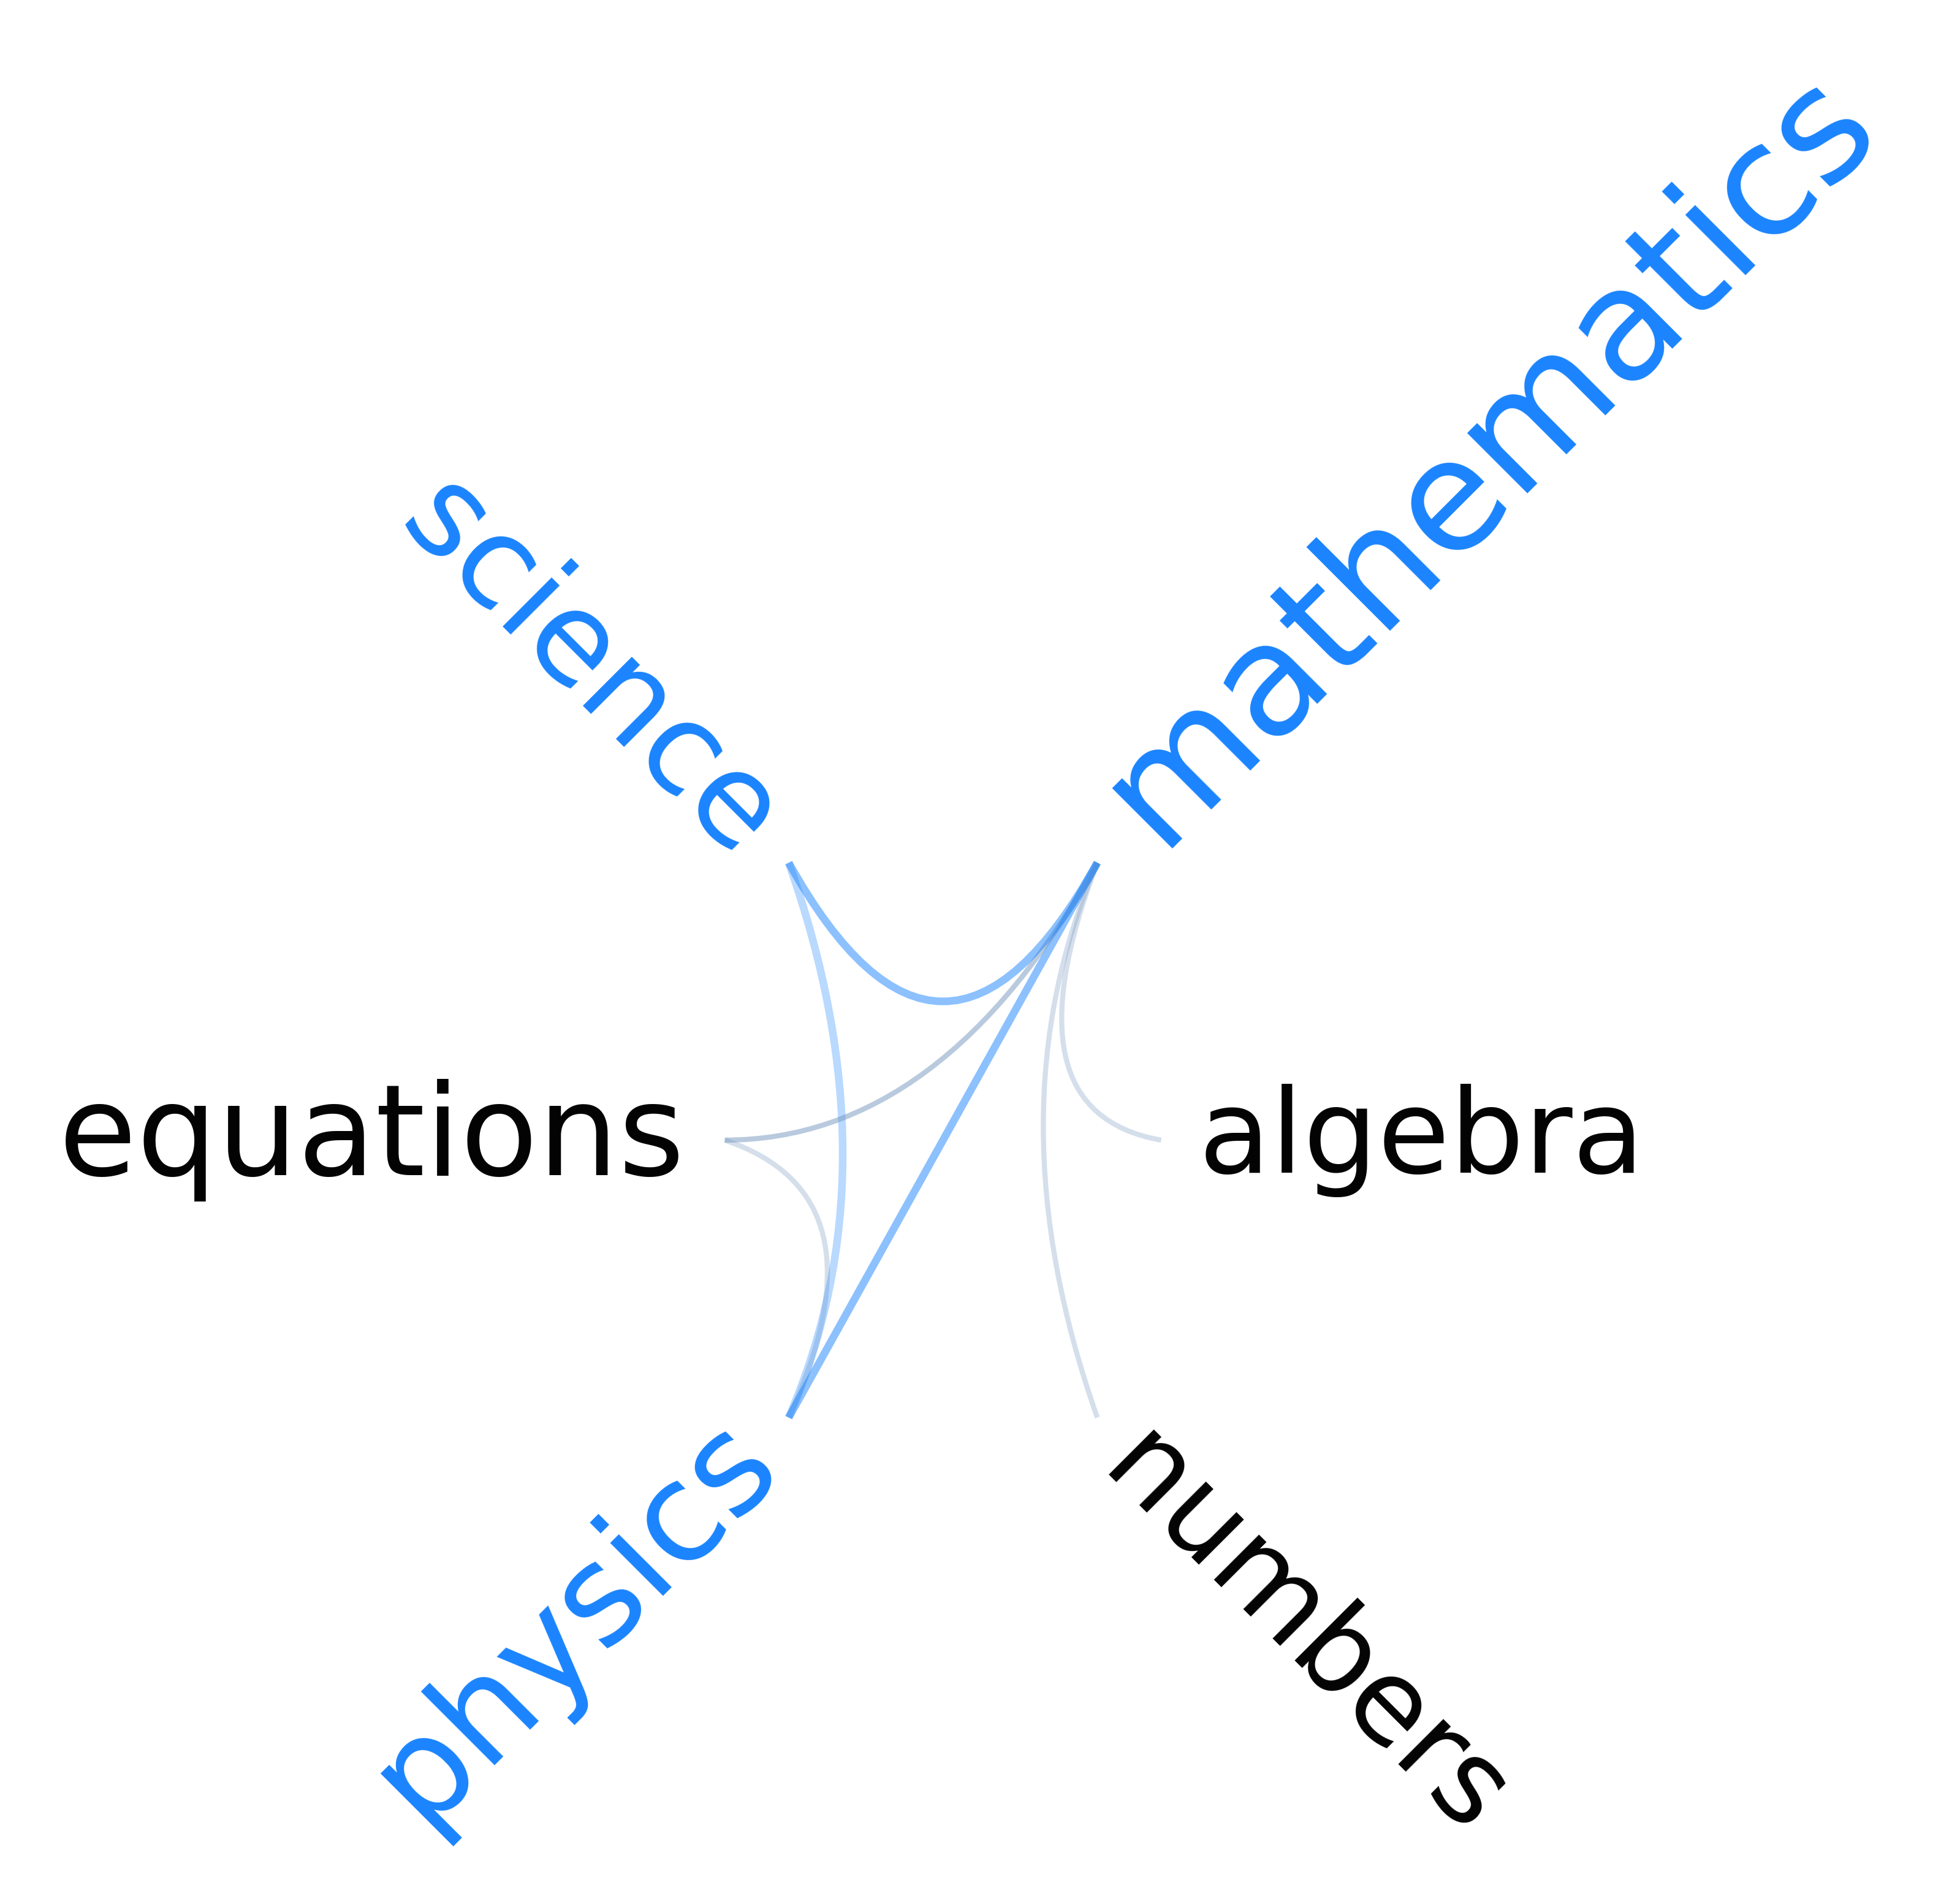

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
/tmp/ipykernel_355889/938665275.py:763: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(png_path, dpi=dpi, bbox_inches="tight", pad_inches=bbox_pad, facecolor="white")
/tmp/ipykernel_355889/938665275.py:764: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(svg_path, bbox_inches="tight", pad_inches=bbox_pad, facecolor="white")


Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_mathematics_edge_bundling_semantic_frame.png
Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_mathematics_edge_bundling_semantic_frame.svg
Processing 1 emotional flowers in batches of 1

Processing flower batch 1/1
Current memory usage: 3460.29 MB
Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_mathematics_emo_flower.png
Error analyzing concreteness for 'mathematics': Empirical sample too small (<3). Found 1 scores.
Skipping 'anxiety': not in network or empty semantic frame.
Skipping 'stress': not in network or empty semantic frame.
Skipping 'depression': not in network or empty semantic frame.
Skipping 'statistics': not in network or empty semantic frame.
Drawing 1 networks in batches of 5

Drawing batch 1/1
Current memory usage: 3441.37 MB
Drawing TFMN: researchers_filtered


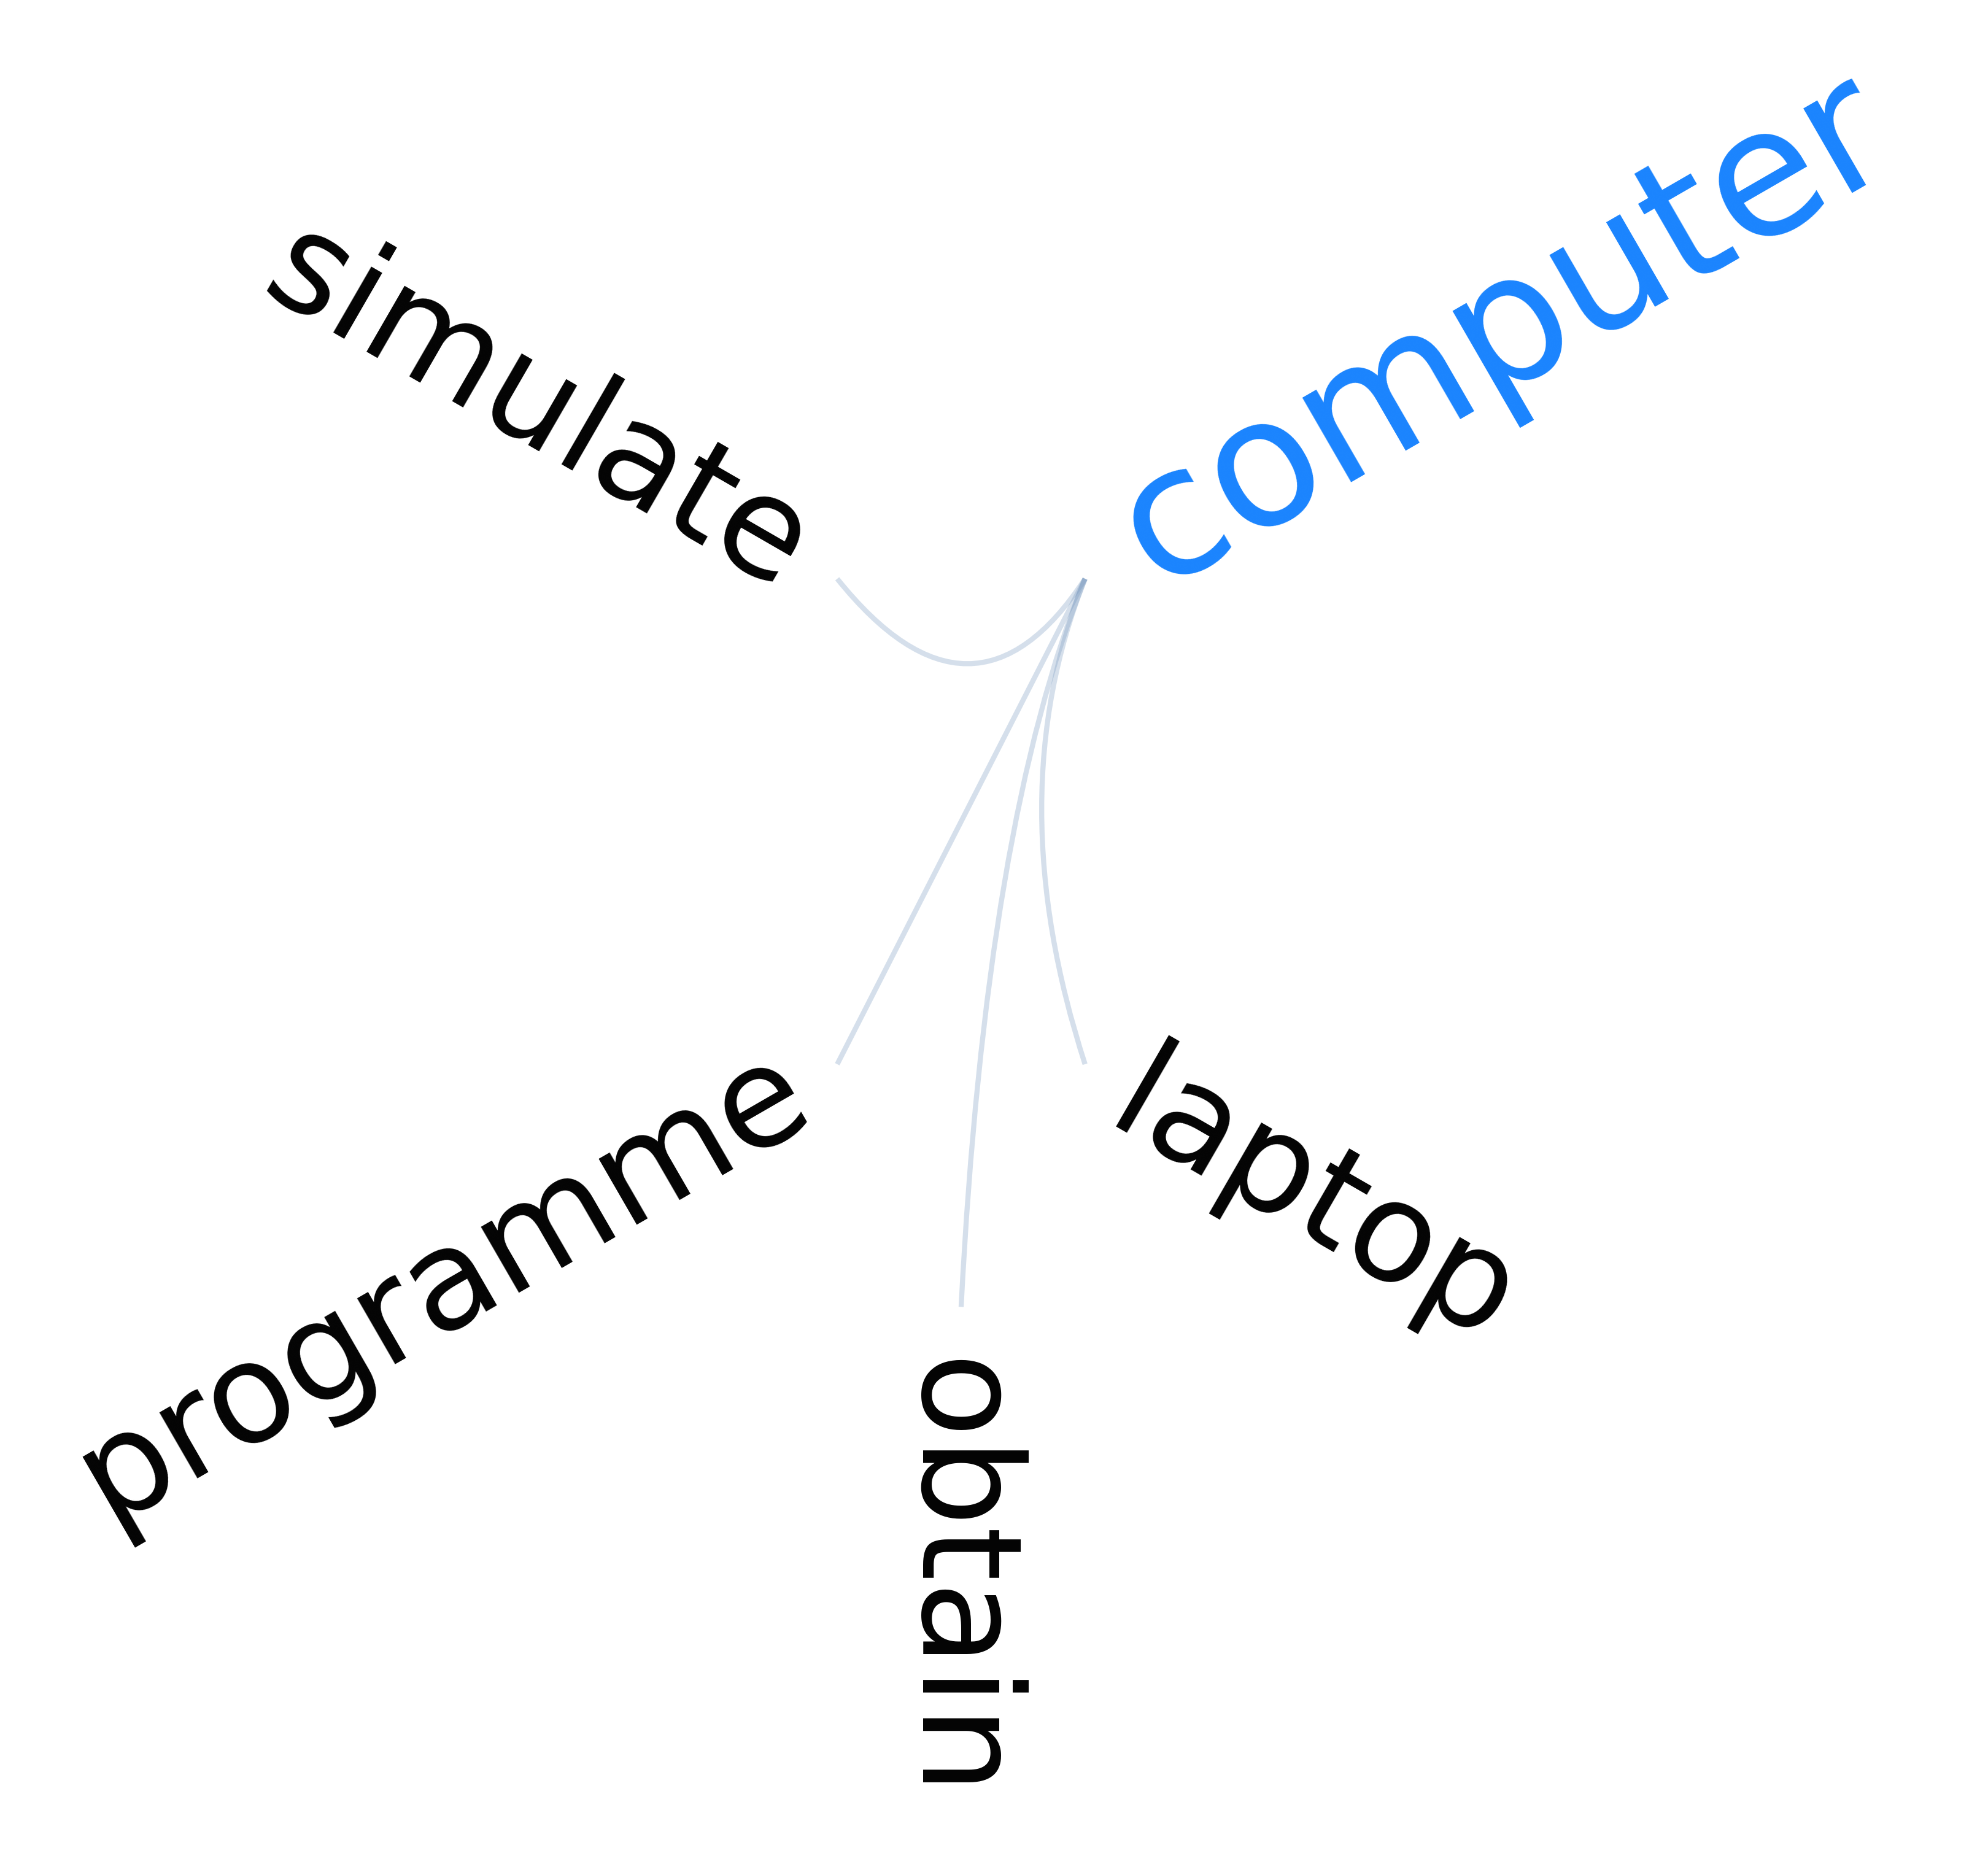

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
/tmp/ipykernel_355889/938665275.py:763: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(png_path, dpi=dpi, bbox_inches="tight", pad_inches=bbox_pad, facecolor="white")
/tmp/ipykernel_355889/938665275.py:764: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(svg_path, bbox_inches="tight", pad_inches=bbox_pad, facecolor="white")


Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_computer_edge_bundling_semantic_frame.png
Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_computer_edge_bundling_semantic_frame.svg
Processing 1 emotional flowers in batches of 1

Processing flower batch 1/1
Current memory usage: 3467.72 MB
Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_computer_emo_flower.png
Error analyzing concreteness for 'computer': Empirical sample too small (<3). Found 1 scores.
Drawing 1 networks in batches of 5

Drawing batch 1/1
Current memory usage: 3441.52 MB
Drawing TFMN: researchers_filtered


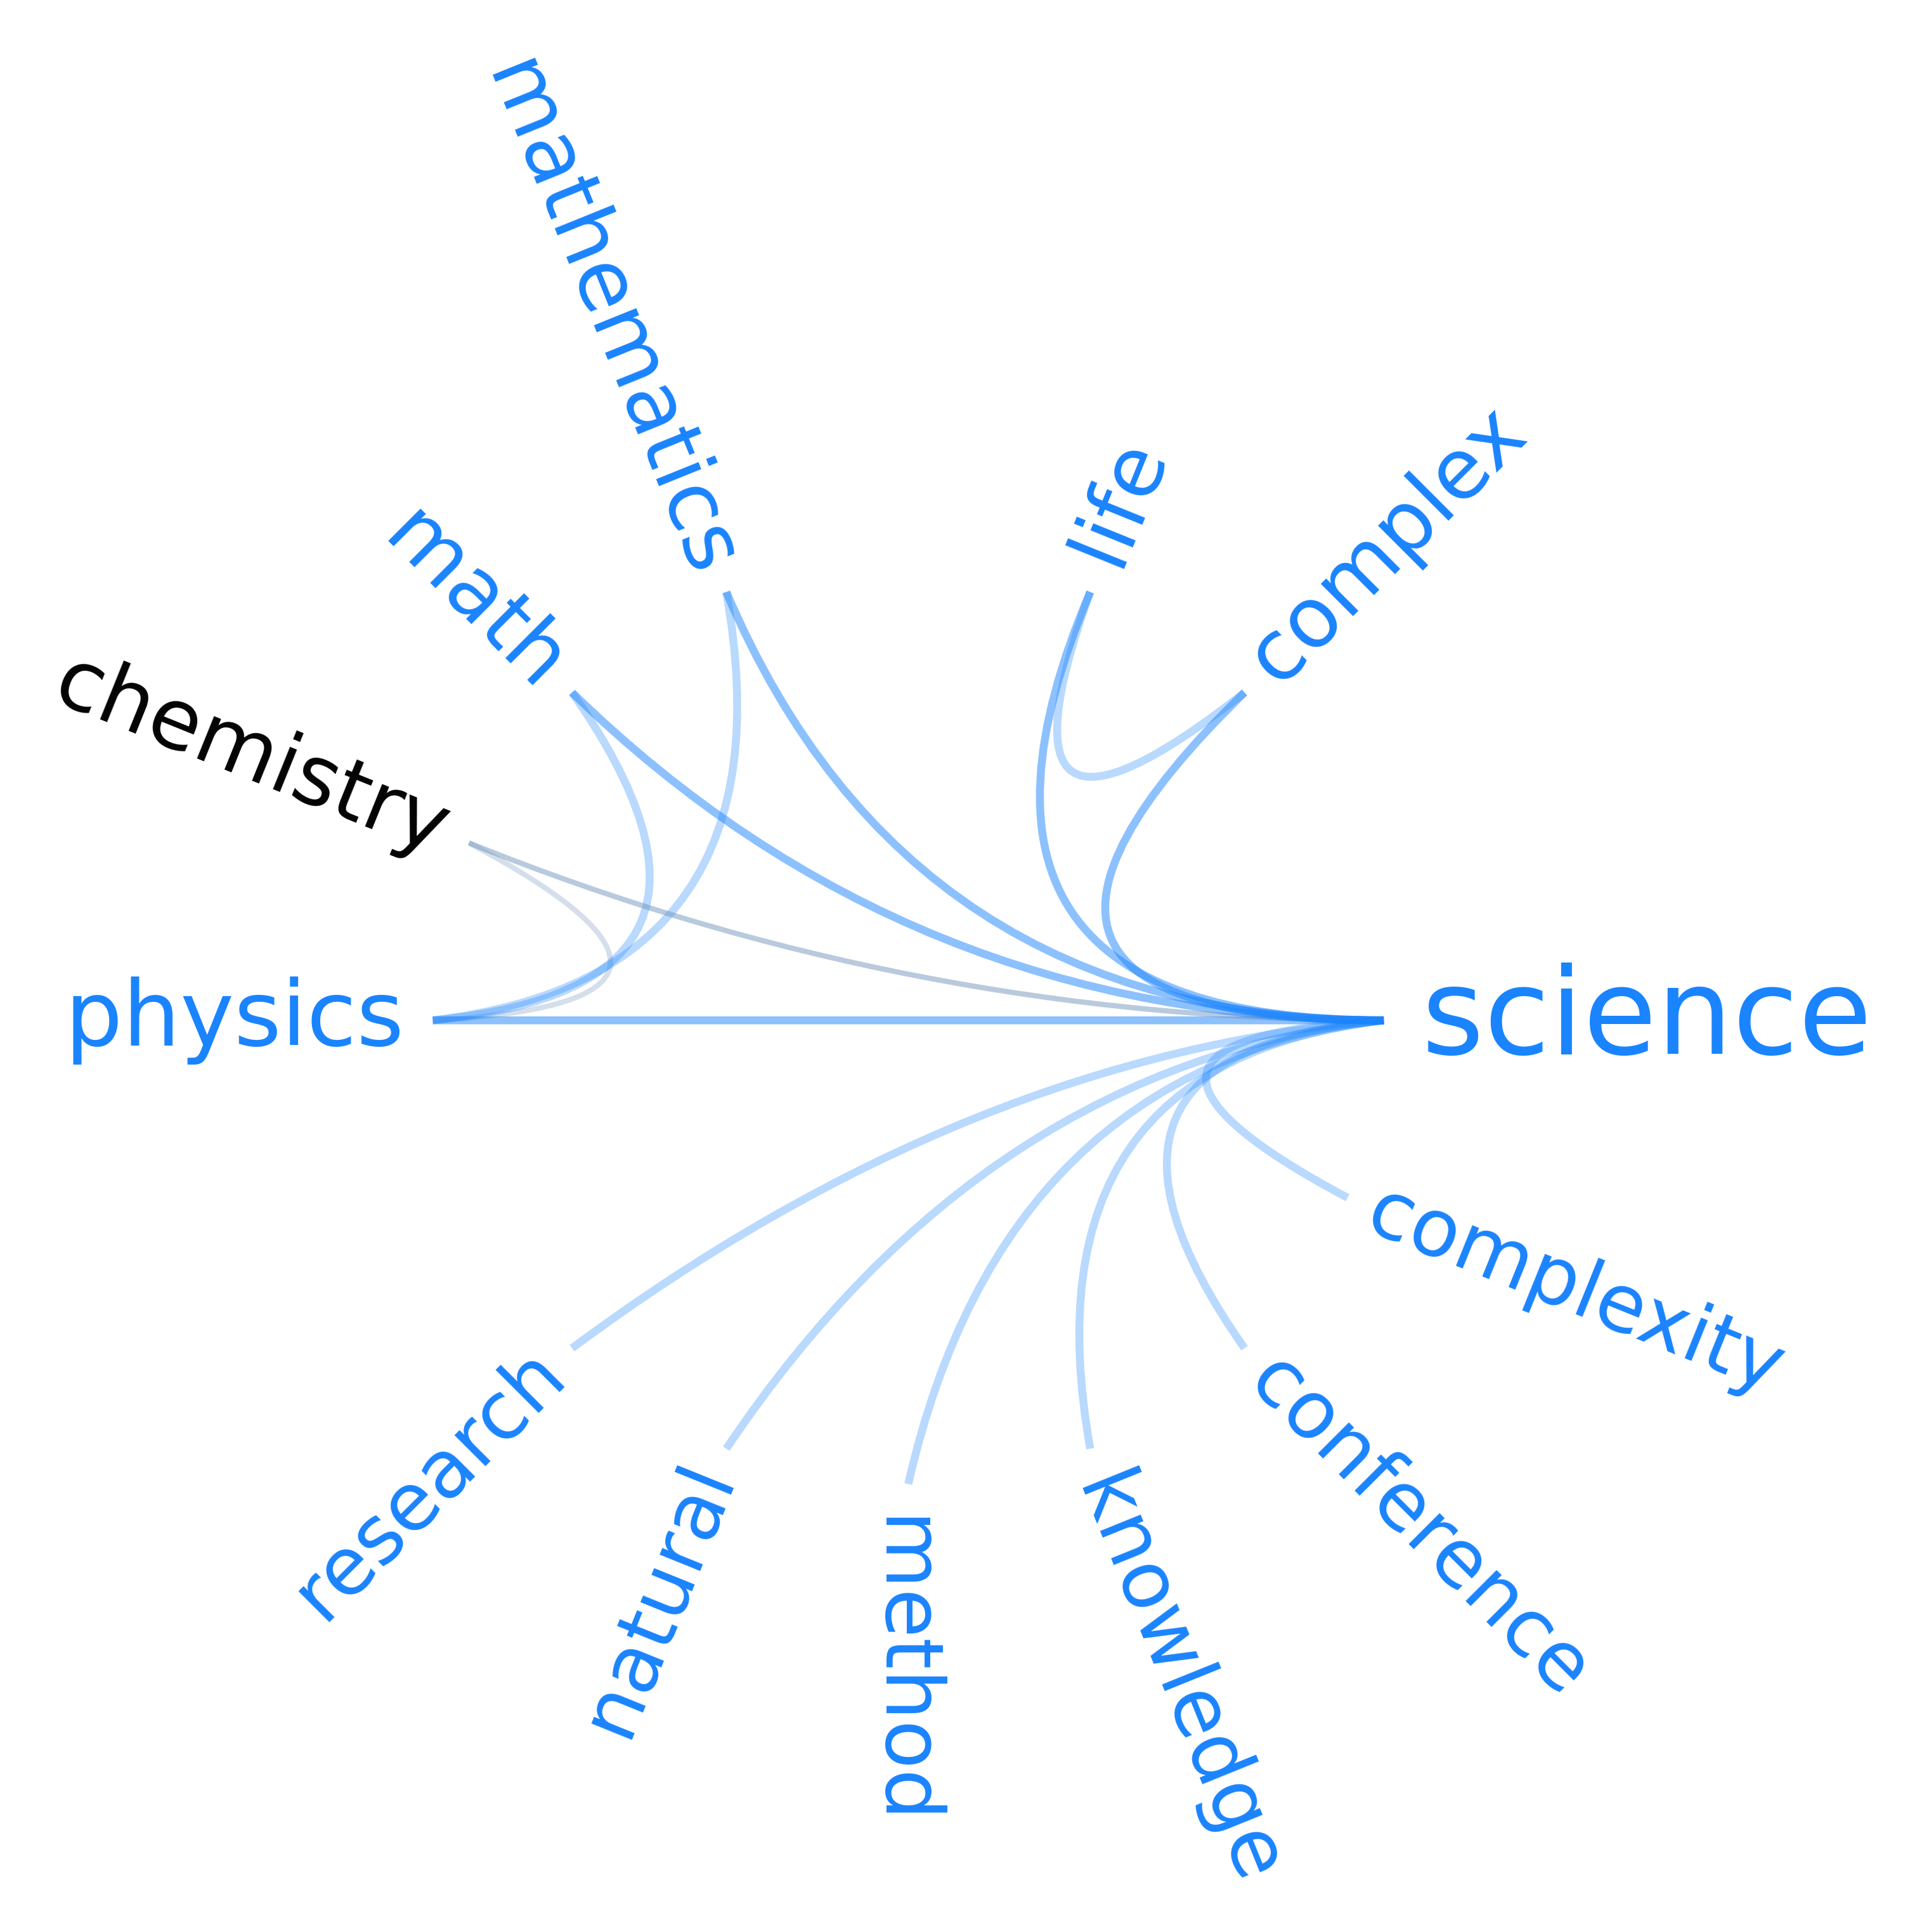

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_science_edge_bundling_semantic_frame.png
Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_science_edge_bundling_semantic_frame.svg
Processing 1 emotional flowers in batches of 1

Processing flower batch 1/1
Current memory usage: 3476.84 MB
Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_science_emo_flower.png
Error analyzing concreteness for 'science': Empirical sample too small (<3). Found 0 scores.
Drawing 1 networks in batches of 5

Drawing batch 1/1
Current memory usage: 3441.52 MB
Drawing TFMN: researchers_filtered


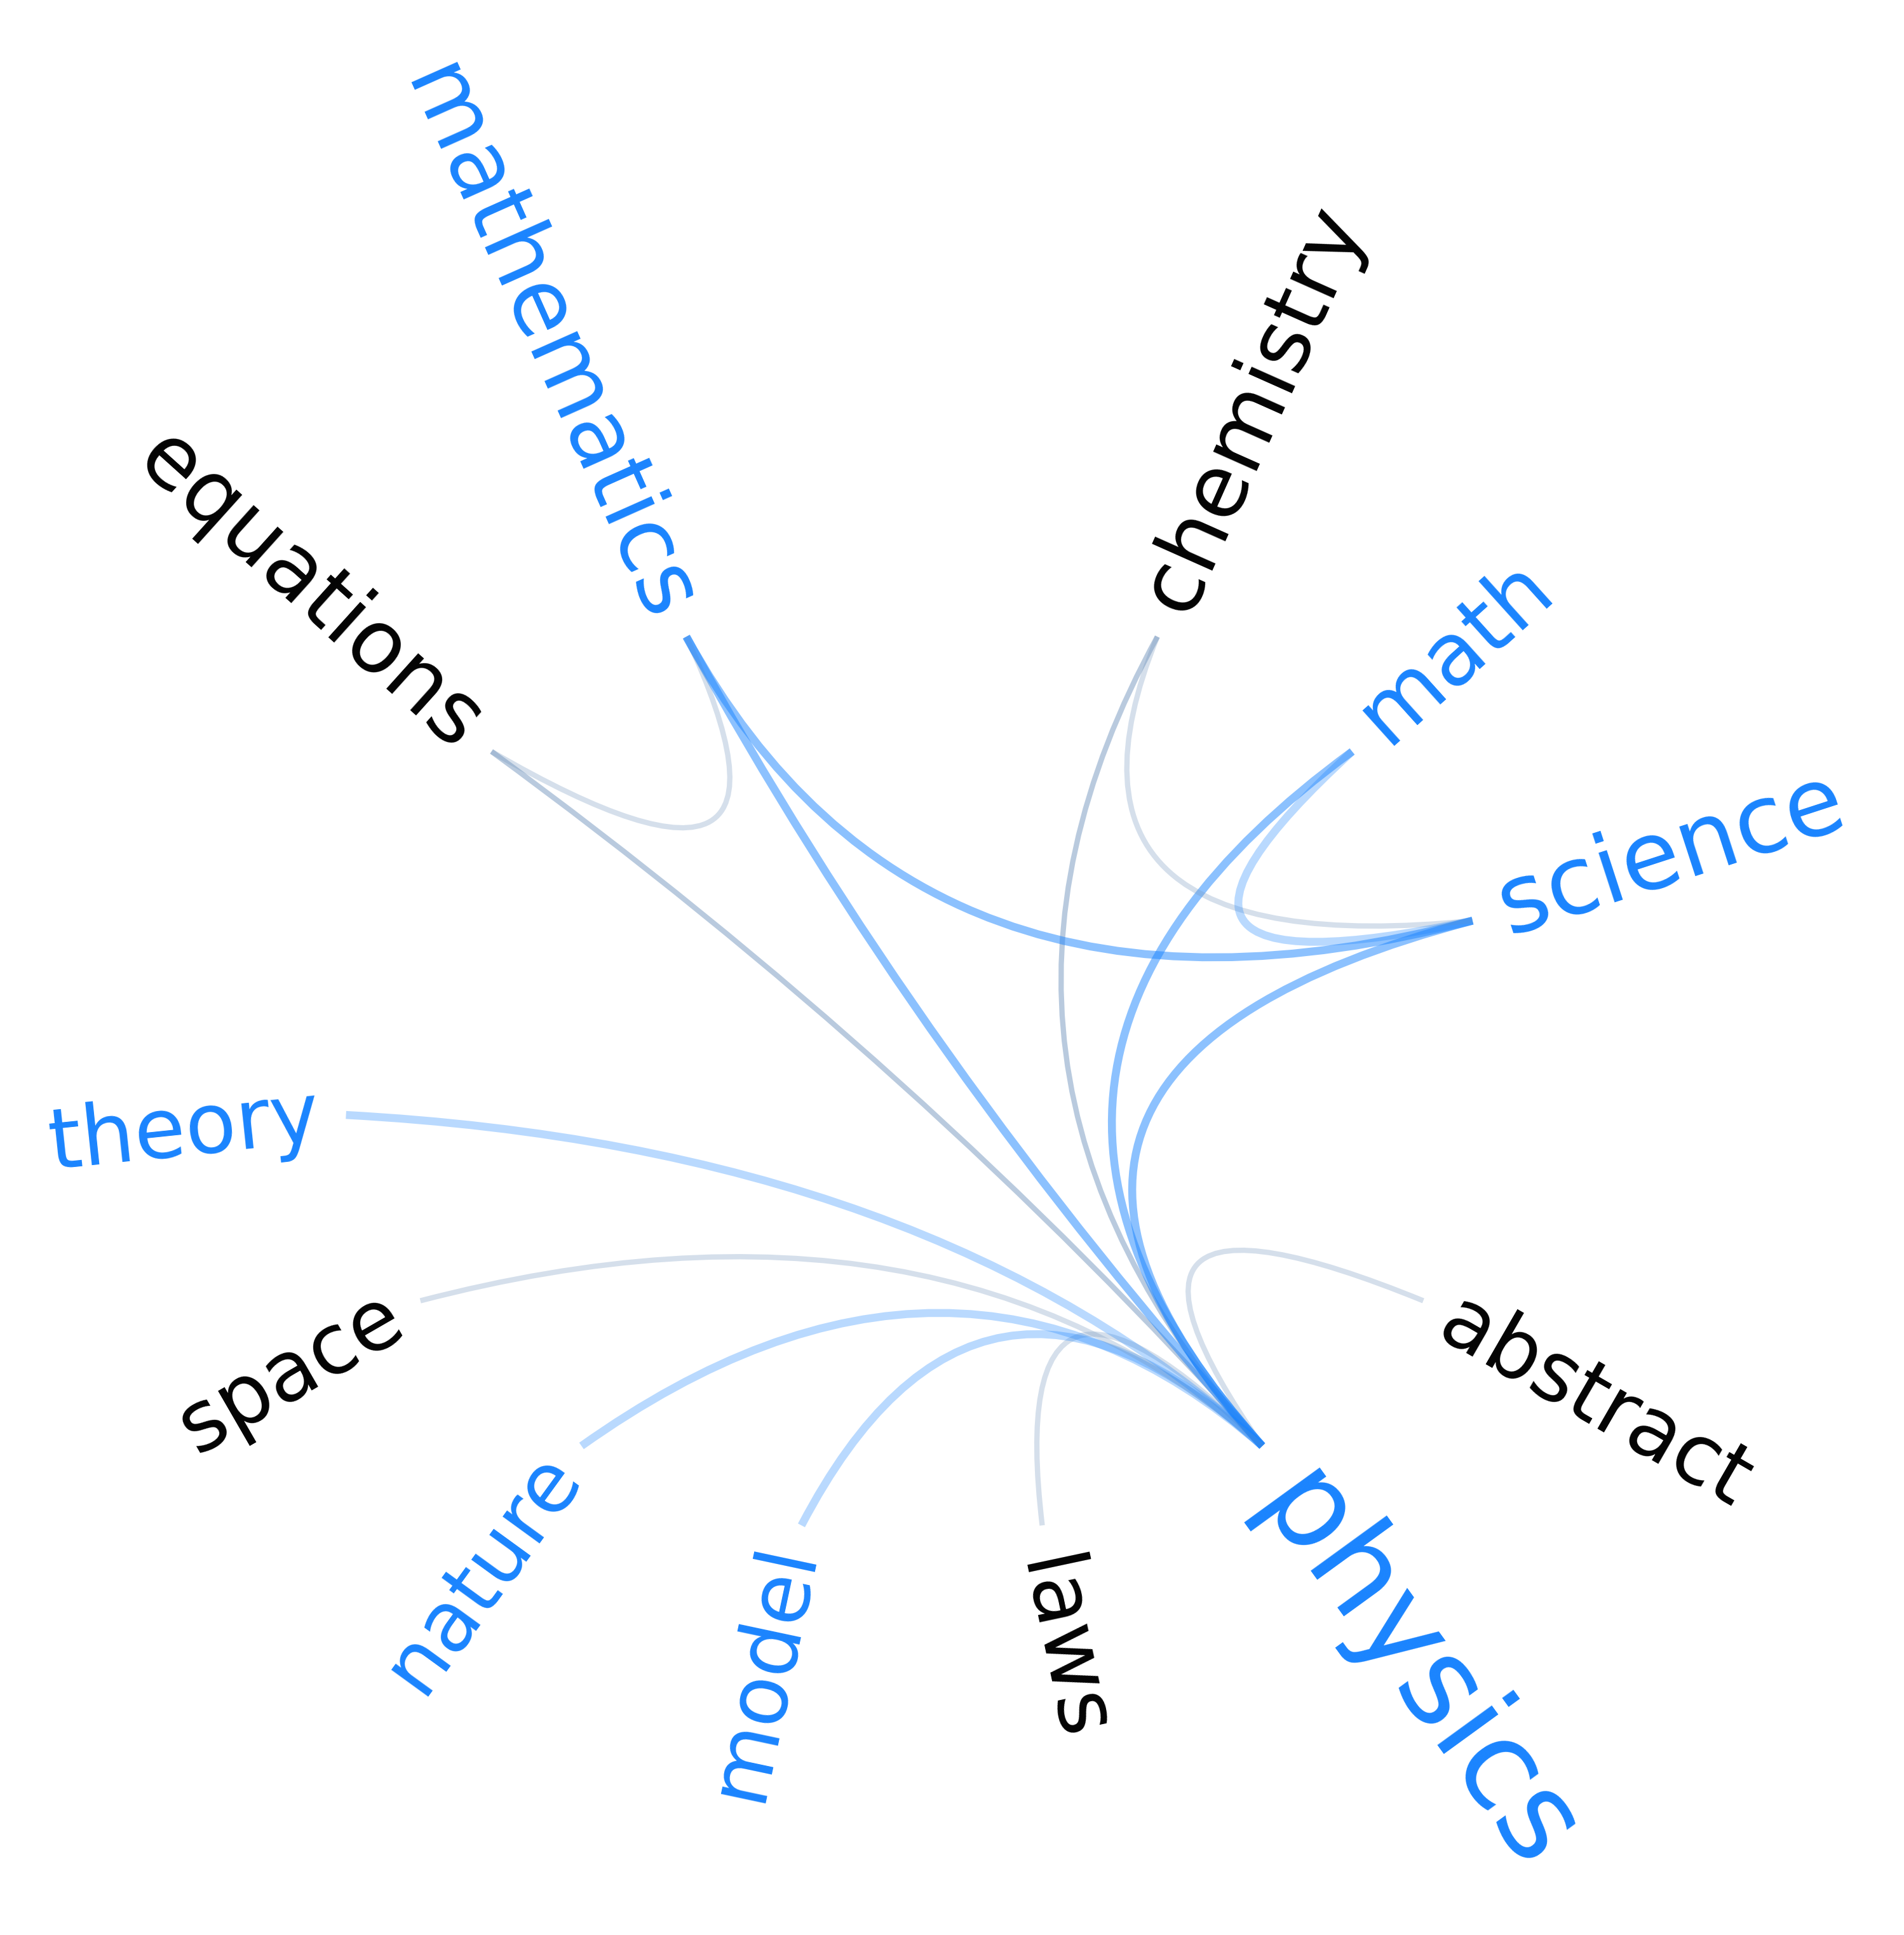

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_physics_edge_bundling_semantic_frame.png
Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_physics_edge_bundling_semantic_frame.svg
Processing 1 emotional flowers in batches of 1

Processing flower batch 1/1
Current memory usage: 3472.33 MB
Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_physics_emo_flower.png
Error analyzing concreteness for 'physics': Empirical sample too small (<3). Found 0 scores.
Drawing 1 networks in batches of 5

Drawing batch 1/1
Current memory usage: 3433.66 MB
Drawing TFMN: researchers_filtered


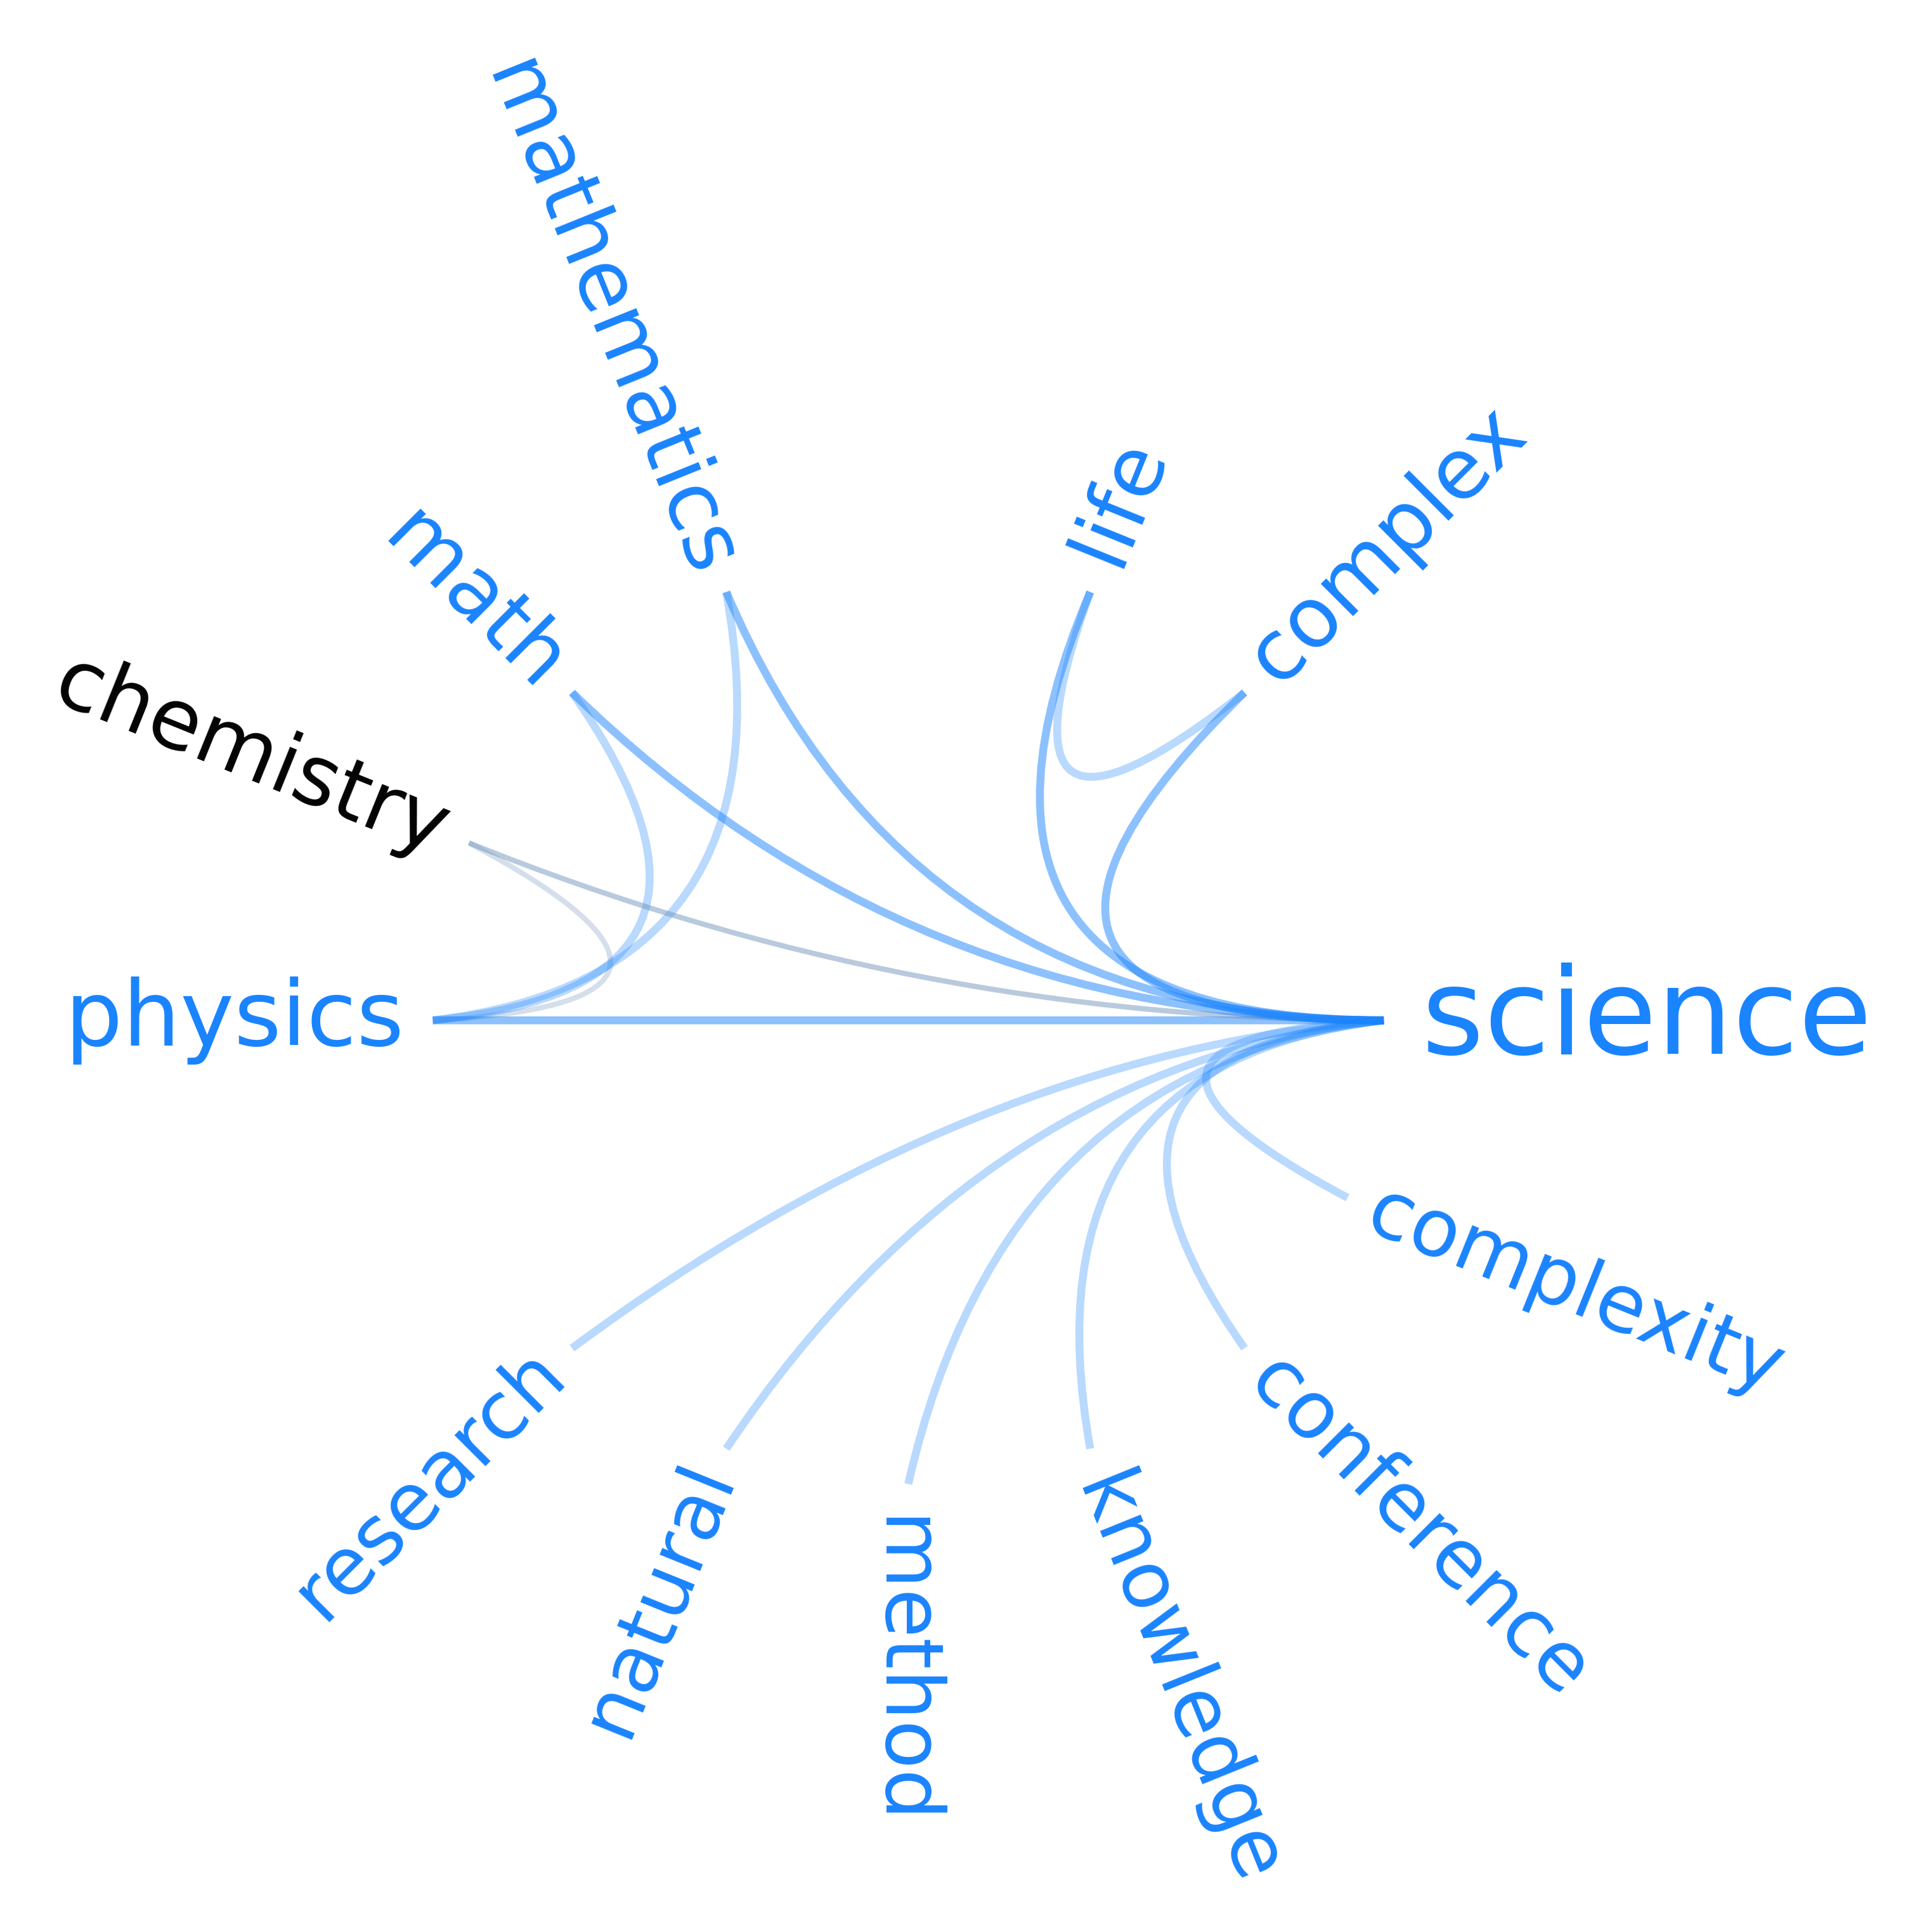

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_science_edge_bundling_semantic_frame.png
Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_science_edge_bundling_semantic_frame.svg
Processing 1 emotional flowers in batches of 1

Processing flower batch 1/1
Current memory usage: 3467.70 MB
Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_science_emo_flower.png
Error analyzing concreteness for 'science': Empirical sample too small (<3). Found 0 scores.
Skipping 'performance': not in network or empty semantic frame.
Skipping 'exam': not in network or empty semantic frame.
Skipping 'grade': not in network or empty semantic frame.
Skipping 'evaluation': not in network or empty semantic frame.
Drawing 1 networks in batches of 5

Drawing batch 1/1
Current memory usage: 3432.38 MB
Drawing TFMN: researchers_filtered


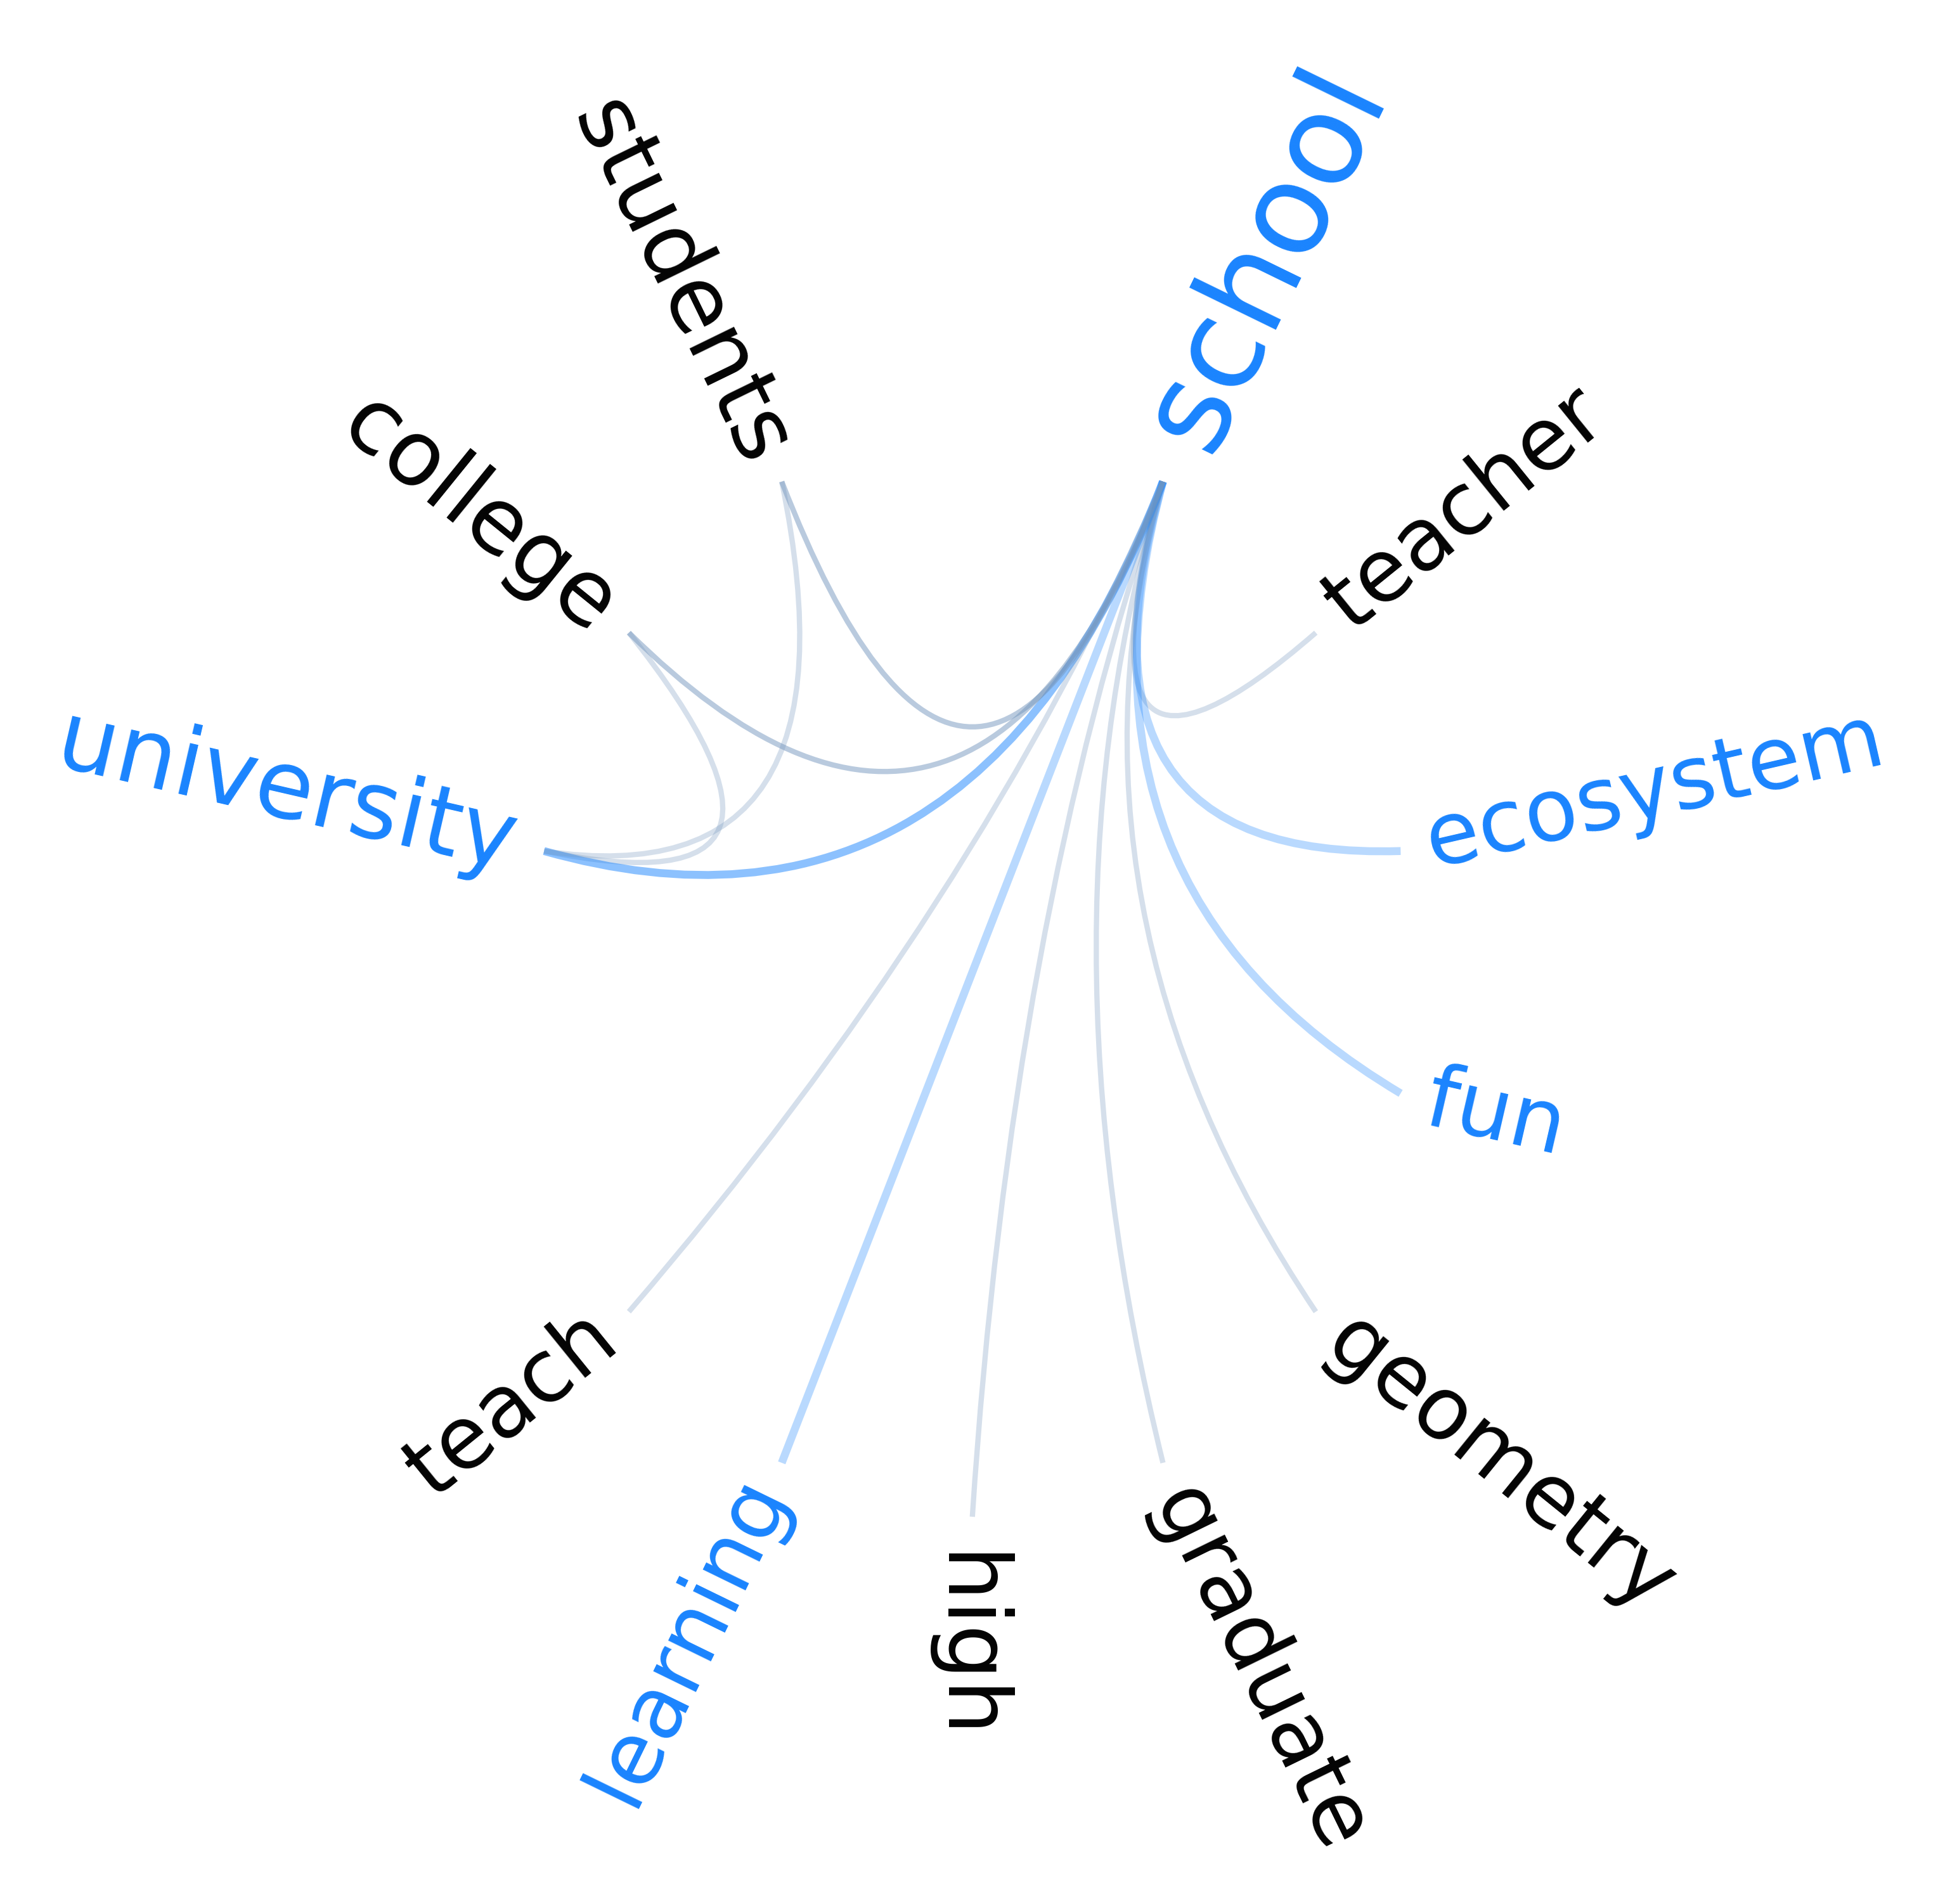

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_school_edge_bundling_semantic_frame.png
Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_school_edge_bundling_semantic_frame.svg
Processing 1 emotional flowers in batches of 1

Processing flower batch 1/1
Current memory usage: 3471.00 MB
Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_school_emo_flower.png
Error analyzing concreteness for 'school': Empirical sample too small (<3). Found 1 scores.
Skipping 'competition': not in network or empty semantic frame.
Drawing 1 networks in batches of 5

Drawing batch 1/1
Current memory usage: 3431.89 MB
Drawing TFMN: researchers_filtered


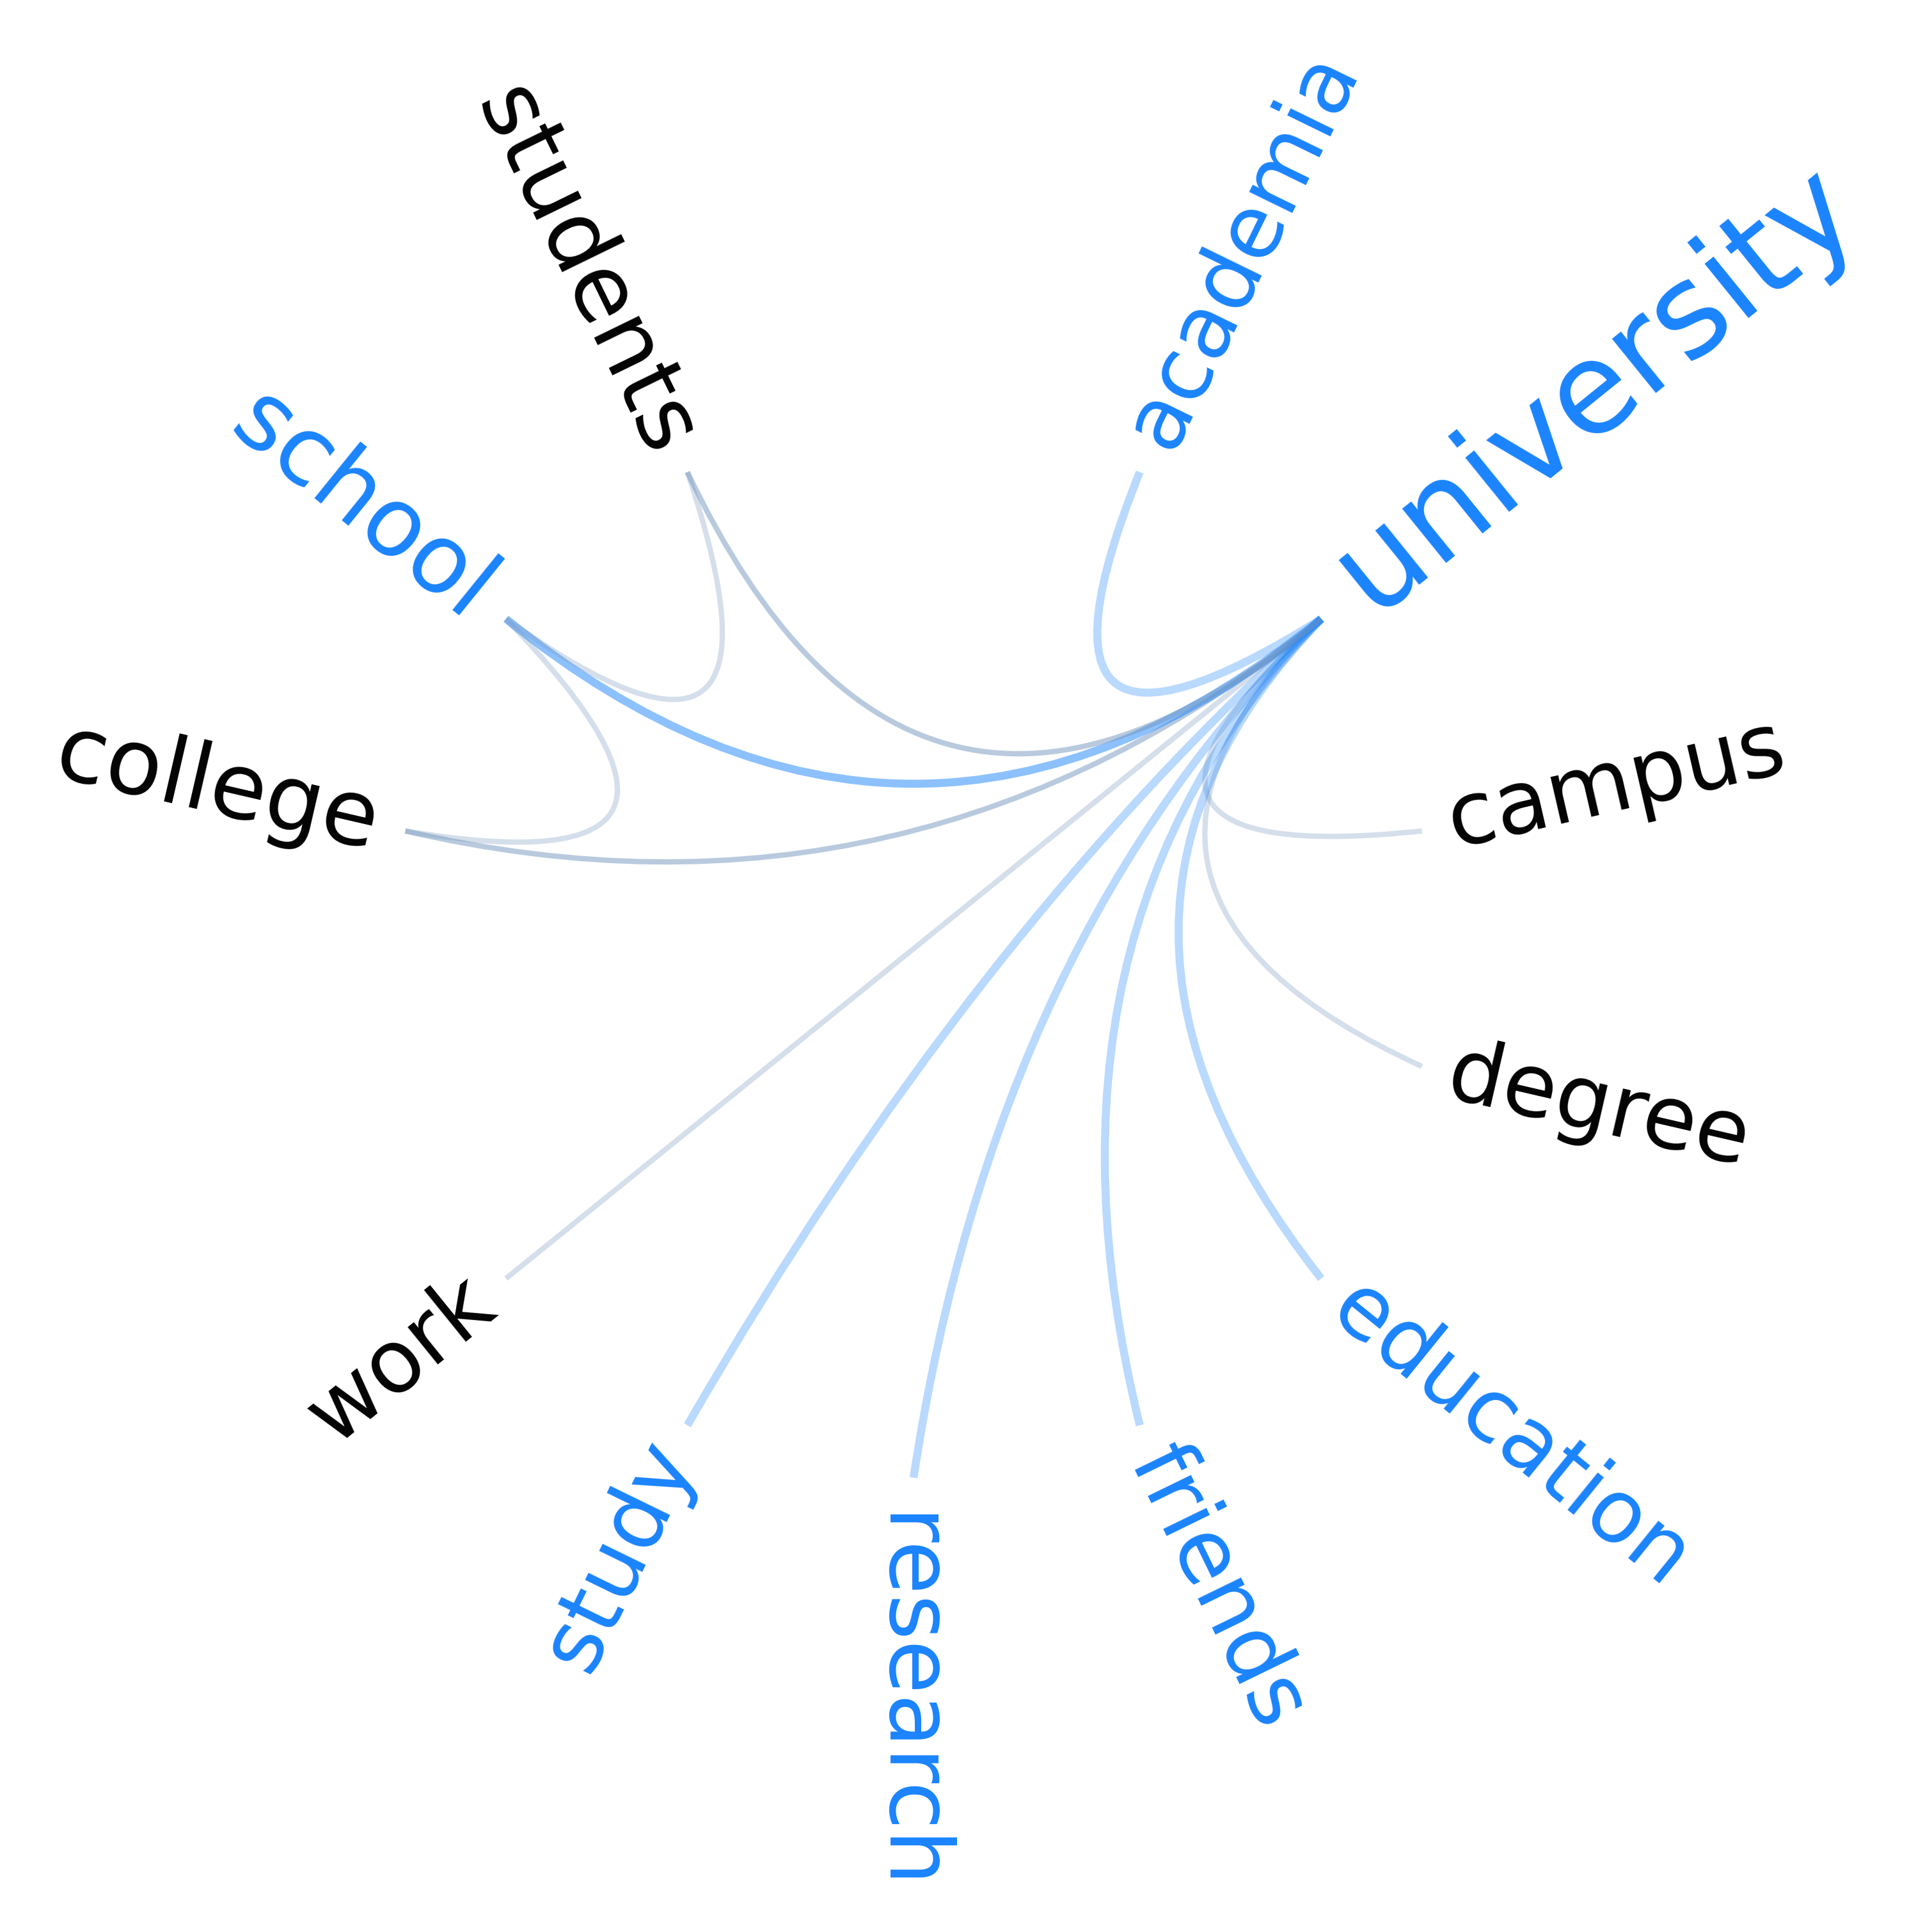

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_university_edge_bundling_semantic_frame.png
Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_university_edge_bundling_semantic_frame.svg
Processing 1 emotional flowers in batches of 1

Processing flower batch 1/1
Current memory usage: 3466.99 MB
Saved ../out/../out/merged/aggregated/researchers_filtered_bfmns/visualizations/researchers_filtered_university_emo_flower.png
Error analyzing concreteness for 'university': Empirical sample too small (<3). Found 2 scores.
Skipping 'calculation': not in network or empty semantic frame.
Skipping 'discipline': not in network or empty semantic frame.
Skipping 'subject': not in network or empty semantic frame.
Current memory usage: 3431.95 MB
Valence stats: {'mean_valence': 0.18055555555555555, 'median_valence': 0.0, 'std_valence': 0.5851492898039138, 'n_positive_nodes': 40, 'n_negative_nodes': 14,

/home/franaz/coding/python/projects/data_science/networks/rassereno/.rassereno-py310/lib/python3.10/site-packages/networkx/algorithms/assortativity/correlation.py:282: RuntimeWarning: invalid value encountered in scalar divide
  r = (t - s) / (1 - s)


Saved at ../out/../out/merged/aggregated/researchers_filtered_bfmns/structural_features/researchers_filtered_structural_features.json
Saved at ../out/../out/merged/aggregated/researchers_filtered_bfmns/structural_features/researchers_filtered_structural_features.txt
Current memory usage: 3432.20 MB
Saved structural features for 1 networks

Data saved to ../out/../out/merged/aggregated/researchers_filtered_bfmns/structural_features/researchers_filtered_structural_features.csv

File researchers_filtered_structural_features.csv already exists in ../out/../out/merged/aggregated/researchers_filtered_bfmns/structural_features. Use overwrite=True to replace it.
FMN: researchers_filtered
Before conversion to nx graph:
144 nodes and 158 edges

After conversion to nx graph:
Graph with 144 nodes and 158 edges

--------------------------------------------
Features for researchers_filtered:
--------------------------------------------
n_nodes 144
n_edges 158
n_positive_nodes 0
n_negative_nodes 0
mi

In [11]:
# Monitor initial memory usage
print("Starting pipeline...\n")

# Import the NetworkX graphs from txt files with custom valences
# Merge multiple edge Students files, filtered + unfiltered edges + student valences:
result = importer.import_fmnt_from_old_text_format(
    files=[
        "../data/students_and_experts_stella_2019/Experts_Filtered.txt",
        "../data/students_and_experts_stella_2019/ValenceExperts.txt"
    ],
    alpha=0.1,
    min_occurrences=3,
    direction_stat="mean",
    directed=False
)

G_merged = result["graph"]
edges_df = result["edges"]
valence_df = result["valence_df"]
custom_valences = result["custom_valences"]

# Build the aggregated BFMN from the graph, keeping the custom valences
merged_fmn = emo.nxgraph_to_formamentis(G_merged)

monitor_memory()

# Export FMNs with custom valences
export_whole_fmn_multiple_custom(
    fmnts=[merged_fmn],
    save_path=files_output_dir,
    filename=f'{group_name}',
    custom_valences=custom_valences
)

# Load Brysbaert concreteness dataset
df_brysbaert = pd.read_csv('../data/brysbaert_concreteness_dataset_eng_ita/brysbaert_concreteness_dataset_eng_ita.csv')

# Draw and save semantic frame plots and emo flowers for each keyword
# for each keyword in keywords extract it, then draw the semantic
# frame plot, save it and show it in the notebook
layout = "edge_bundling"
if len(keywords) > 0:
    for keyword in keywords:
        semantic_frame = emo.extract_word_from_formamentis(merged_fmn, keyword)
        if not hasattr(semantic_frame, "vertices") or len(semantic_frame.vertices) == 0:
            print(f"Skipping '{keyword}': not in network or empty semantic frame.")
            continue
        out_dir = f'{base_output_path}/{files_output_dir}/visualizations'
        filename = f'{group_name}_{keyword}_{layout}_semantic_frame'
        draw_fmnts(
            fmnts={group_name: semantic_frame},
            out_dir=out_dir,
            layout=layout,
            highlight=[],
            thickness=1,
            ax=None,
            custom_valences=custom_valences,
            filename_base=filename,
        )
        make_emo_flowers(
            fmnts={f'{group_name}_{keyword}': semantic_frame},
            save_path=out_dir,
            filename=f'{group_name}_{keyword}_emo_flower',
            emo=emo,
            batch_size=1
        )

        # Analyze concreteness of the semantic frame
        try:
            result = analyze_semantic_frame_concreteness(
                semantic_frame,
                df_brysbaert,
                seed=None,
                save_json_path=f'{base_output_path}/{files_output_dir}/analysis/{group_name}_{keyword}_concreteness_analysis.json',
                save_figure_path=f'{base_output_path}/{files_output_dir}/visualizations/{group_name}_{keyword}_concreteness_analysis.png',
                plot=True
            )
            print(result['p_value'])
            print(f"Concreteness analysis for '{keyword}' saved successfully.")
        except Exception as e:
            print(f"Error analyzing concreteness for '{keyword}': {e}")

monitor_memory()

valence_stats = fmn_valence.fmn_valence_stats(merged_fmn, custom_valences)
print("Valence stats:", valence_stats)

print(G_merged)
print("Graph:", G_merged.nodes(data=True))
print("Custom valences:", custom_valences)

# Make a dictionary of the merged BFMN for further processing
if merged_fmn is not None:
    bfmns = {fmn_type: merged_fmn}

# Compute node_valence_maps for the merged BFMN
# Collect node valences separately (cannot attach to namedtuple)
node_val_maps = {}
node_val_maps[fmn_type] = {n: d.get("valence_cat") for n, d in G_merged.nodes(data=True)}

'''valence_stats = fmn_valence.fmn_valence_stats(merged_fmn, custom_valences)
print("Valence stats:", valence_stats)

# Inspect the merged BFMN
inspect_fmn(
    fmn=merged_fmn,
    participant=group_name,
    all_features={group_name: valence_stats},
    emo=emo
)'''

# Check for presence of each keyword in the fmn
fmtools.verify_and_report_nodes(
    fmns={group_name: merged_fmn},
    required=keywords
)

# Compute and export structural features for the aggregated FMN
aggregated_features = extract_bfmn_structural_features(
    fmnts={group_name: merged_fmn},
    save_path=f'{base_output_path}/{files_output_dir}/structural_features',
    emo=emo,
    batch_size=1,
    node_valence_maps=None,
    persist=True
)

# Convert features to DataFrame and export
aggregated_features_df = all_fmns_features_df(aggregated_features, orient="participants")
exporter.export_df(aggregated_features_df, f'{base_output_path}/{files_output_dir}/structural_features', filename=f'{group_name}_structural_features')

aggregated_features_df = all_fmns_features_df(aggregated_features, orient="participants")
exporter.export_df(aggregated_features_df, f'{base_output_path}/{files_output_dir}/structural_features', filename=f'{group_name}_structural_features')

# Inspect the created fmnts
inspect_fmn(
    fmn=merged_fmn,
    participant=group_name,
    all_features=aggregated_features,
    emo=emo
)

### Verifying keywords presence in the networks

In [12]:
# Verify presence of nodes "ansia", "matematica", "stress" and "depressione" in all BFMNs
check_summary = fmtools.verify_and_report_nodes(
    fmns={fmn_type: merged_fmn},
    required=keywords,
)

print(check_summary)

Presence of nodes ['mathematics', 'anxiety', 'stress', 'depression', 'statistics', 'computer', 'science', 'physics', 'science', 'performance', 'exam', 'grade', 'evaluation', 'school', 'competition', 'university', 'calculation', 'discipline', 'subject'] in all FMNs:
FMN 'researchers_filtered_bfmns' missing: ['anxiety', 'stress', 'depression', 'statistics', 'performance', 'exam', 'grade', 'evaluation', 'competition', 'calculation', 'discipline', 'subject']

Networks satisfying (ALL of ['mathematics', 'anxiety', 'stress', 'depression', 'statistics', 'computer', 'science', 'physics', 'science', 'performance', 'exam', 'grade', 'evaluation', 'school', 'competition', 'university', 'calculation', 'discipline', 'subject']): 0/1 (0.00%)
Presence 'mathematics': 1/1 (100.00%)

Presence 'anxiety': 0/1 (0.00%)

Presence 'stress': 0/1 (0.00%)

Presence 'depression': 0/1 (0.00%)

Presence 'statistics': 0/1 (0.00%)

Presence 'computer': 1/1 (100.00%)

Presence 'science': 2/1 (200.00%)

Presence 'physic

In [13]:
# Print number of nodes and edges (are the same as the ones imported: good!)
print(f"\nBFMN 2024 has {len(merged_fmn.vertices)} nodes and {len(merged_fmn.edges)} edges.")
print(f"BFMN 2025 has {len(merged_fmn.vertices)} nodes and {len(merged_fmn.edges)} edges.")

valence_stats_2025 = fmn_valence.fmn_valence_stats(merged_fmn, custom_valences)
print("Valence stats 2025:", valence_stats_2025)


BFMN 2024 has 144 nodes and 158 edges.
BFMN 2025 has 144 nodes and 158 edges.
Valence stats 2025: {'mean_valence': 0.18055555555555555, 'median_valence': 0.0, 'std_valence': 0.5851492898039138, 'n_positive_nodes': 40, 'n_negative_nodes': 14, 'n_neutral_nodes': 90, 'total_nodes': 144}
